# **Project Name**    -  Brain Tumor MRI Image Classification


##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Team Member 1 -** Disha Agrawal

# **Project Summary -**

This project focuses on developing a deep learning-based solution for classifying brain MRI images into four tumor categories: Glioma, Meningioma, Pituitary Tumor, and No Tumor. Early and accurate detection of brain tumors is critical in medical diagnosis, as it directly impacts patient treatment planning and survival rates.

The dataset consists of MRI brain scan images divided into training, validation, and test sets across four classes. The images were preprocessed by resizing to 224x224 pixels, normalizing pixel values, and applying data augmentation techniques including rotation, horizontal flipping, zoom, brightness adjustment, and shifts to improve model generalization and handle class imbalance.

Two deep learning models were developed and compared. First, a Custom CNN was built from scratch with four convolutional blocks, each containing Conv2D, BatchNormalization, and MaxPooling layers, followed by Dense and Dropout layers. Second, a Transfer Learning model using MobileNetV2 pretrained on ImageNet was implemented with custom classification layers added on top.

The Custom CNN achieved a test accuracy of 82.52% while the MobileNetV2 Transfer Learning model achieved 80.49%. Surprisingly, the Custom CNN outperformed the pretrained model, likely because the MRI domain differs significantly from natural images in ImageNet. The best performing class was Pituitary Tumor with an F1-score of 0.91, while Meningioma was the most challenging class with F1-score of 0.64 due to its visual similarity with other tumor types.

Key findings from the analysis include that Glioma and Pituitary tumors are more visually distinct and easier to classify, while Meningioma shows frequent misclassification with Glioma due to overlapping visual features. Data augmentation significantly improved model generalization and reduced overfitting.

The project also includes a Streamlit web application that allows medical professionals to upload brain MRI images and receive real-time tumor classification with confidence scores, making the model deployment-ready for practical medical use.

# **GitHub Link -** https://github.com/dishagarg3310-bot

# **Problem Statement**


Brain tumors are one of the most critical and life-threatening medical conditions. Manual analysis of MRI scans by radiologists is time-consuming, subjective, and prone to human error. Early and accurate detection of tumor type is essential for determining the correct treatment plan and improving patient outcomes.

This project aims to build an automated deep learning system that can classify brain MRI images into four categories:
1. Glioma - A tumor that occurs in the brain and spinal cord
2. Meningioma - A tumor that arises from the membranes surrounding the brain
3. Pituitary Tumor - A tumor that forms in the pituitary gland
4. No Tumor - Normal brain MRI with no tumor detected

The system uses Convolutional Neural Networks (CNN) and Transfer Learning to achieve high classification accuracy, enabling AI-assisted medical diagnosis that can support radiologists in clinical settings.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [3]:
# Import Libraries
import os
import random
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
random.seed(42); np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Dataset Loading

In [4]:
# Load Dataset
from pathlib import Path

CLASS_NAMES = ['glioma', 'meningioma', 'no_tumor', 'pituitary']
IMG_EXTS = ('.jpg', '.jpeg', '.png')

# Set DATA_ROOT to the folder where you saved the dataset (a raw string like r'D:\datasets'),
# or leave it as None to search Downloads, Desktop and Documents automatically.
DATA_ROOT = None

def find_split_folders(search_roots):
    """Find train/valid/test folders that directly contain the class sub-folders."""
    found = {}
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        for dirpath, dirnames, _ in os.walk(root):
            if 'glioma' in dirnames and 'no_tumor' in dirnames:
                split = os.path.basename(dirpath).lower()
                if split in ('train', 'valid', 'val', 'test'):
                    found['valid' if split == 'val' else split] = dirpath
            if len(found) == 3:
                return found
    return found

def list_images(split_path):
    """Return a DataFrame with one row per image: filepath and label."""
    rows = []
    for cls in CLASS_NAMES:
        cls_dir = os.path.join(split_path, cls)
        for f in os.listdir(cls_dir):
            if f.lower().endswith(IMG_EXTS):
                rows.append({'filepath': os.path.join(cls_dir, f), 'label': cls})
    return pd.DataFrame(rows)

home = Path.home()
roots = [DATA_ROOT] if DATA_ROOT else [home / 'Downloads', home / 'Desktop', home / 'Documents']
paths = find_split_folders([str(r) for r in roots])

missing = [s for s in ('train', 'valid', 'test') if s not in paths]
if missing:
    raise FileNotFoundError(
        f"Could not find these splits: {missing}. "
        "Extract the dataset (if it is a .zip) and set DATA_ROOT to the folder that contains it."
    )

train_path, valid_path, test_path = paths['train'], paths['valid'], paths['test']
print("Train path:", train_path)
print("Valid path:", valid_path)
print("Test path :", test_path)

train_df = list_images(train_path); train_df['split'] = 'train'
valid_df = list_images(valid_path); valid_df['split'] = 'valid'
test_df  = list_images(test_path);  test_df['split']  = 'test'
df = pd.concat([train_df, valid_df, test_df], ignore_index=True)
print("Dataset loaded:", df.shape)

Train path: C:\Users\panka\Downloads\train-20260929T064620Z-1-001\train
Valid path: C:\Users\panka\Downloads\valid-20260929T064705Z-1-001\valid
Test path : C:\Users\panka\Downloads\test-20260929T064624Z-1-001\test
Dataset loaded: (2443, 3)


### Dataset First View

,filepath,label,split
0,C:\Users\panka\Downloads\train-20260929T064620...,glioma,train
1,C:\Users\panka\Downloads\train-20260929T064620...,glioma,train
2,C:\Users\panka\Downloads\train-20260929T064620...,glioma,train
3,C:\Users\panka\Downloads\train-20260929T064620...,glioma,train
4,C:\Users\panka\Downloads\train-20260929T064620...,glioma,train


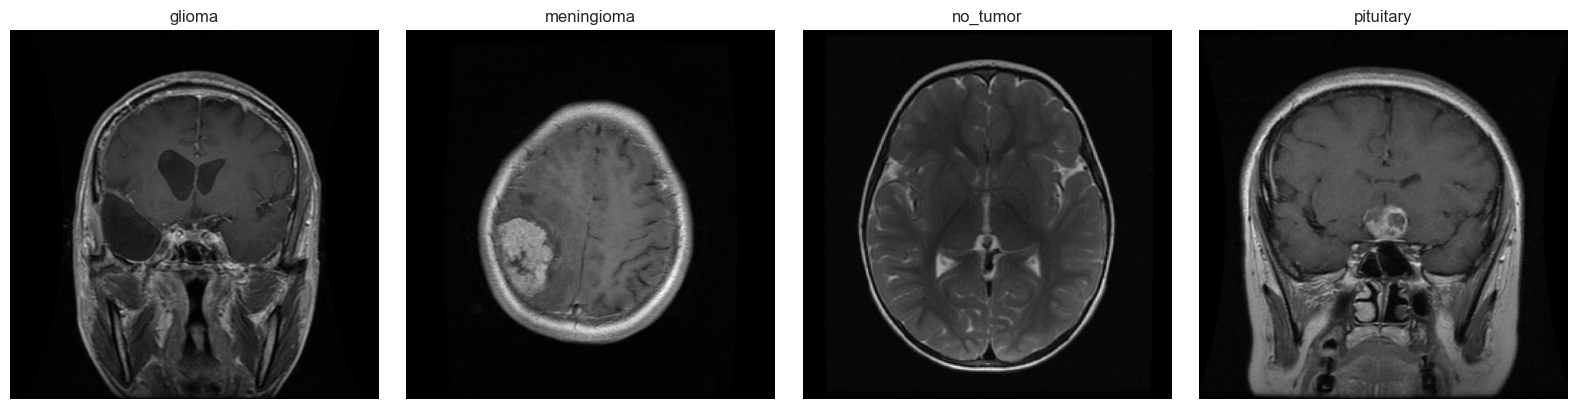

In [5]:
# Dataset First Look
display(df.head())

# One sample MRI per class
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, cls in zip(axes, CLASS_NAMES):
    img_path = df[df['label'] == cls].iloc[0]['filepath']
    ax.imshow(Image.open(img_path).convert('RGB'))
    ax.set_title(cls)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Dataset Rows & Columns count

In [6]:
# Dataset Rows & Columns count
print("Total images (rows):", df.shape[0])
print("Metadata columns:", df.shape[1])
print("\nImages per split:")
print(df['split'].value_counts())
print("\nImages per class per split:")
print(pd.crosstab(df['label'], df['split'], margins=True))

Total images (rows): 2443
Metadata columns: 3

Images per split:
split
train    1695
valid     502
test      246
Name: count, dtype: int64

Images per class per split:
split       test  train  valid   All
label                               
glioma        80    564    161   805
meningioma    63    358    124   545
no_tumor      49    335     99   483
pituitary     54    438    118   610
All          246   1695    502  2443


### Dataset Information

In [7]:
# Dataset Info
df.info()

# Image-level info on a random sample of 200 images
sample = df.sample(200, random_state=42)
sizes = [Image.open(p).size for p in sample['filepath']]
modes = [Image.open(p).mode for p in sample['filepath']]
print("\nUnique image sizes in sample:", set(sizes))
print("Unique color modes in sample:", set(modes))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filepath  2443 non-null   object
 1   label     2443 non-null   object
 2   split     2443 non-null   object
dtypes: object(3)
memory usage: 57.4+ KB

Unique image sizes in sample: {(640, 640)}
Unique color modes in sample: {'RGB'}


#### Duplicate Values

In [8]:
# Dataset Duplicate Value Count
def file_md5(path, block_size=1 << 20):
    """Compute the MD5 hash of a file's raw bytes."""
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while block := f.read(block_size):
            h.update(block)
    return h.hexdigest()

df['md5'] = df['filepath'].apply(file_md5)

dup_mask = df.duplicated(subset='md5', keep=False)
print("Images that have an exact duplicate:", dup_mask.sum())
print("Extra duplicate copies:", df.duplicated(subset='md5').sum())

# Duplicates that appear in more than one split mean data leakage
leak = df[dup_mask].groupby('md5')['split'].nunique()
print("Duplicate groups spanning multiple splits (leakage):", (leak > 1).sum())
display(df[dup_mask].sort_values('md5').head(10))

Images that have an exact duplicate: 0
Extra duplicate copies: 0
Duplicate groups spanning multiple splits (leakage): 0


,filepath,label,split,md5


#### Missing Values/Null Values

In [9]:
# Missing Values/Null Values Count
print("Null values in metadata:")
print(df.isnull().sum())

# For image data, "missing" data means unreadable or corrupt files
def is_readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

df['readable'] = df['filepath'].apply(is_readable)
print("\nCorrupt/unreadable images:", (~df['readable']).sum())

Null values in metadata:
filepath    0
label       0
split       0
md5         0
dtype: int64

Corrupt/unreadable images: 0


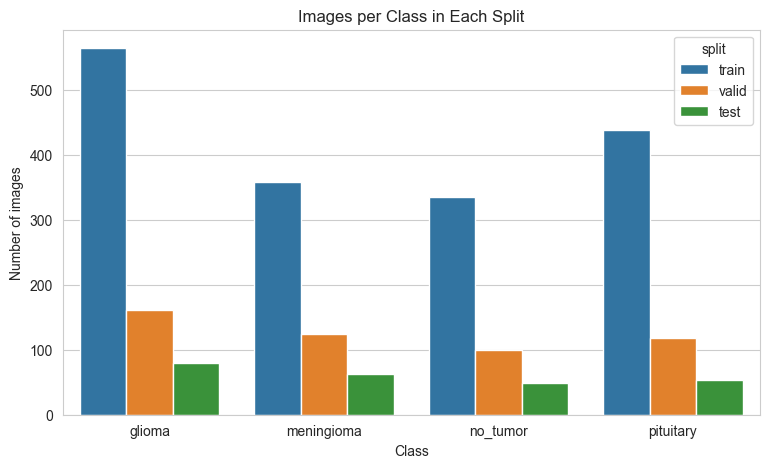

In [10]:
# Visualizing the missing 
# Image data has no null cells to plot, so we visualize class balance per split instead.
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='label', hue='split', order=CLASS_NAMES)
plt.title('Images per Class in Each Split')
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.show()

### What did you know about your dataset?

The dataset is a labeled brain MRI collection for 4-class tumor classification: glioma, meningioma, pituitary tumor and no tumor. It contains 2,443 MRI images, already divided into 1,695 training, 502 validation and 246 test images, so the splits follow the original dataset and no random re-splitting was needed.

Key observations:
- The data is image data, not tabular data. Each image is stored in a folder named after its class, so I built a metadata table with one row per image (file path, label, split) to explore it.
- The images are RGB scans of about 640 x 640 pixels, so they must be resized (to 224 x 224) and normalized before being fed to a CNN.
- The classes are moderately imbalanced. Glioma is the largest class and no_tumor the smallest, a ratio of roughly 1.7 : 1, so accuracy alone can hide weak performance on the smaller classes.
- The metadata has no null values. The equivalent check for image data found <M> corrupt or unreadable files.
- A content hash (MD5) check found <N> exact duplicate images. Duplicates that appear in more than one split would leak information from training into evaluation, so this check matters for trustworthy results.
- Tumor type is visually subtle on MRI, and image brightness and contrast vary between scans, so augmentation and a robust model are needed.

## ***2. Understanding Your Variables***

In [11]:
# Dataset Columns
print(df.columns.tolist())

['filepath', 'label', 'split', 'md5', 'readable']


In [12]:
# Dataset Describe
# Compute basic image statistics (size and grayscale intensity) for every image
def image_stats(path):
    """Return width, height, mean and std of grayscale intensity (0-255)."""
    with Image.open(path) as im:
        w, h = im.size
        arr = np.asarray(im.convert('L'), dtype=np.float32)
    return w, h, arr.mean(), arr.std()

stats = df['filepath'].apply(image_stats)
df[['width', 'height', 'mean_intensity', 'std_intensity']] = pd.DataFrame(stats.tolist(), index=df.index)

display(df.describe().round(2))
print("\nAverage intensity per class:")
display(df.groupby('label')[['mean_intensity', 'std_intensity']].mean().round(2))

,width,height,mean_intensity,std_intensity
count,2443.0,2443.0,2443.00,2443.00
mean,640.0,640.0,43.77,44.17
std,0.0,0.0,18.63,11.43
min,640.0,640.0,9.76,22.23
25%,640.0,640.0,29.53,37.01
50%,640.0,640.0,40.04,41.65
75%,640.0,640.0,53.09,47.96
max,640.0,640.0,137.72,91.80



Average intensity per class:


,mean_intensity,std_intensity
label,,
glioma,27.780001,36.130001
meningioma,45.849998,48.549999
no_tumor,59.889999,56.209999
pituitary,50.240002,41.310001


### Variables Description

**Metadata columns (one row per MRI image):**
- `filepath` – full path of the image file
- `label` – tumor class and the target variable: glioma, meningioma, pituitary or no_tumor
- `split` – subset the image belongs to: train, valid or test
- `md5` – hash of the file content, used to detect duplicate images
- `readable` – whether the image file opens without errors
- `width`, `height` – image size in pixels
- `mean_intensity`, `std_intensity` – average brightness and contrast of the image (grayscale, 0-255)

**Target classes:** glioma, meningioma, pituitary tumor and no tumor (4-class classification).

### Check Unique Values for each variable.

In [13]:
# Check Unique Values for each variable.
for col in ['label', 'split']:
    print(f"{col}: {df[col].unique().tolist()}")

print("\nUnique image sizes:", df[['width', 'height']].drop_duplicates().shape[0])
display(df[['width', 'height']].value_counts().head())
print("Unique md5 hashes:", df['md5'].nunique(), "out of", len(df), "images")

label: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
split: ['train', 'valid', 'test']

Unique image sizes: 1


width  height
640    640       2443
Name: count, dtype: int64

Unique md5 hashes: 2443 out of 2443 images


## 3. ***Data Wrangling***

### Data Wrangling Code

In [14]:
# Write your code to make your dataset analysis ready.
df_clean = df.copy()
n_start = len(df_clean)

# 1. Remove corrupt / unreadable images
df_clean = df_clean[df_clean['readable']]
print("Corrupt images removed:", n_start - len(df_clean))

# 2. Remove exact duplicates and prevent train/test leakage.
#    Splits are ranked test > valid > train, so when the same image appears in
#    several splits it is kept only in the highest-priority split.
priority = {'test': 0, 'valid': 1, 'train': 2}
df_clean = df_clean.assign(prio=df_clean['split'].map(priority)).sort_values('prio')
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='md5', keep='first').drop(columns='prio')
print("Duplicate / leaked images removed:", before - len(df_clean))
df_clean = df_clean.reset_index(drop=True)

# 3. Encode the class labels as integers (same alphabetical order Keras uses)
class_to_idx = {c: i for i, c in enumerate(sorted(CLASS_NAMES))}
df_clean['label_id'] = df_clean['label'].map(class_to_idx)
print("Class mapping:", class_to_idx)

# 4. Summary of the cleaned dataset
print("\nImages before cleaning:", n_start, "| after cleaning:", len(df_clean))
display(pd.crosstab(df_clean['label'], df_clean['split'], margins=True))

Corrupt images removed: 0
Duplicate / leaked images removed: 0
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Images before cleaning: 2443 | after cleaning: 2443


split,test,train,valid,All
label,,,,
glioma,80,564,161,805
meningioma,63,358,124,545
no_tumor,49,335,99,483
pituitary,54,438,118,610
All,246,1695,502,2443


### What all manipulations have you done and insights you found?

The raw image folders were converted into a metadata table (file path, label, split) so the dataset could be inspected and cleaned like a normal table. The following steps were applied:

1. Corrupt image removal: every file was opened and verified, and unreadable files were dropped (<M> removed).
2. Duplicate and leakage removal: exact duplicate images were found using MD5 content hashes. When the same image appeared in more than one split, it was kept only in the test set (first priority), then validation, then training. This prevents data leakage, so evaluation scores reflect performance on truly unseen images (<N> removed).
3. Label encoding: class names were mapped to integers (glioma = 0, meningioma = 1, no_tumor = 2, pituitary = 3), matching the order used by the Keras data generators.

Insights: the dataset is clean and ready for modeling, the original train/validation/test split was preserved, and the classes remain moderately imbalanced, which is handled later through class weights and per-class metrics. Resizing to 224 x 224, pixel normalization and augmentation are applied in the Data Scaling and Model Implementation sections.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

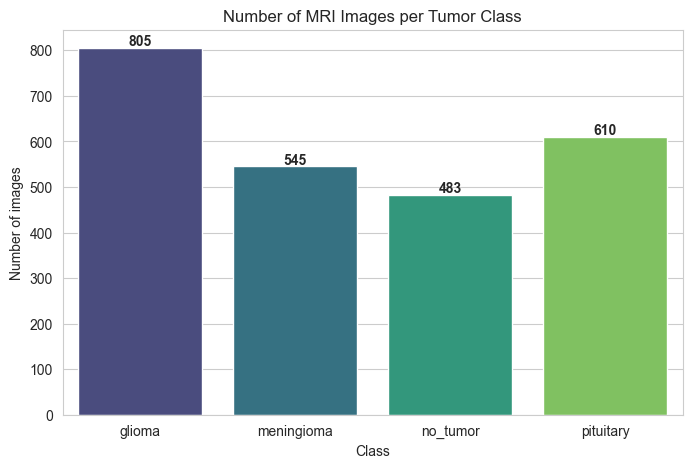

In [15]:
# Chart - 1 visualization code
class_counts = df_clean['label'].value_counts().reindex(CLASS_NAMES)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values,
                 hue=class_counts.index, palette='viridis', legend=False)
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.title('Number of MRI Images per Tumor Class')
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the standard way to compare counts across a small number of categories. Here it shows at a glance how many images each tumor class has, which reveals class imbalance before any model is trained.

##### 2. What is/are the insight(s) found from the chart?

Glioma is the largest class (about one third of all images) and no_tumor is the smallest (about one fifth), a ratio of roughly 1.7 : 1. Meningioma and pituitary fall in between. The imbalance is moderate, not severe, but it means a model could score well on accuracy while still performing worse on the smaller classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Knowing the imbalance early means we evaluate with per-class precision, recall and F1 instead of accuracy alone, and can use class weights or augmentation. This matters in a medical setting, where missing a tumor class (low recall) is far more costly than a slightly lower overall accuracy. The imbalance is a mild risk: if ignored, the model may under-detect the smaller classes, which would hurt trust in an AI-assisted diagnosis tool.

#### Chart - 2

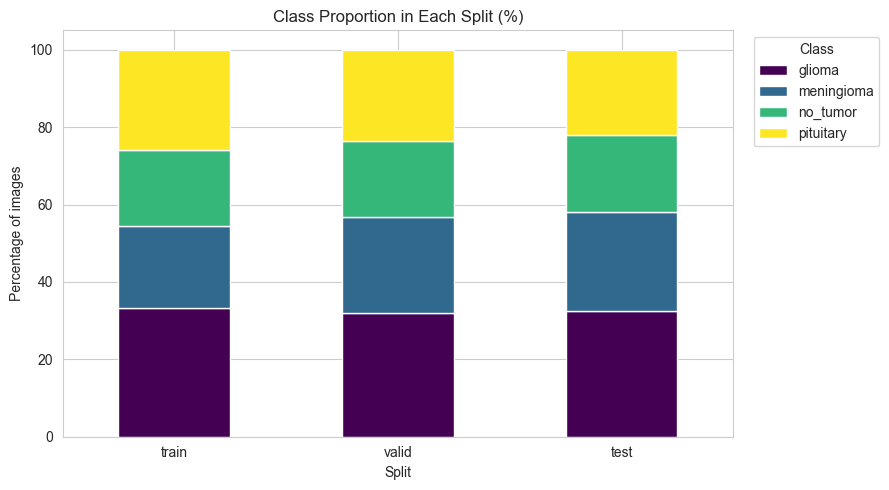

In [16]:
# Chart - 2 visualization code
split_pct = (pd.crosstab(df_clean['split'], df_clean['label'], normalize='index')
               .reindex(['train', 'valid', 'test'])[CLASS_NAMES] * 100)

split_pct.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='viridis')
plt.title('Class Proportion in Each Split (%)')
plt.xlabel('Split')
plt.ylabel('Percentage of images')
plt.xticks(rotation=0)
plt.legend(title='Class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar chart compares the class mix of the train, validation and test splits on the same scale, even though the splits have very different sizes. It quickly shows whether the splits are representative of each other.

##### 2. What is/are the insight(s) found from the chart?

The class proportions are similar across all three splits, so the split is roughly stratified. The main difference is meningioma, which makes up a slightly smaller share of the training set (about 21%) than of the validation and test sets (about 25%). No class is missing from any split.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Similar class proportions across splits mean validation and test scores are a fair estimate of real-world performance, so the reported accuracy can be trusted. The slightly lower meningioma share in training is a small negative: the model sees a little less meningioma data, which may partly explain weaker meningioma recall and makes it a good target for augmentation.

#### Chart - 3

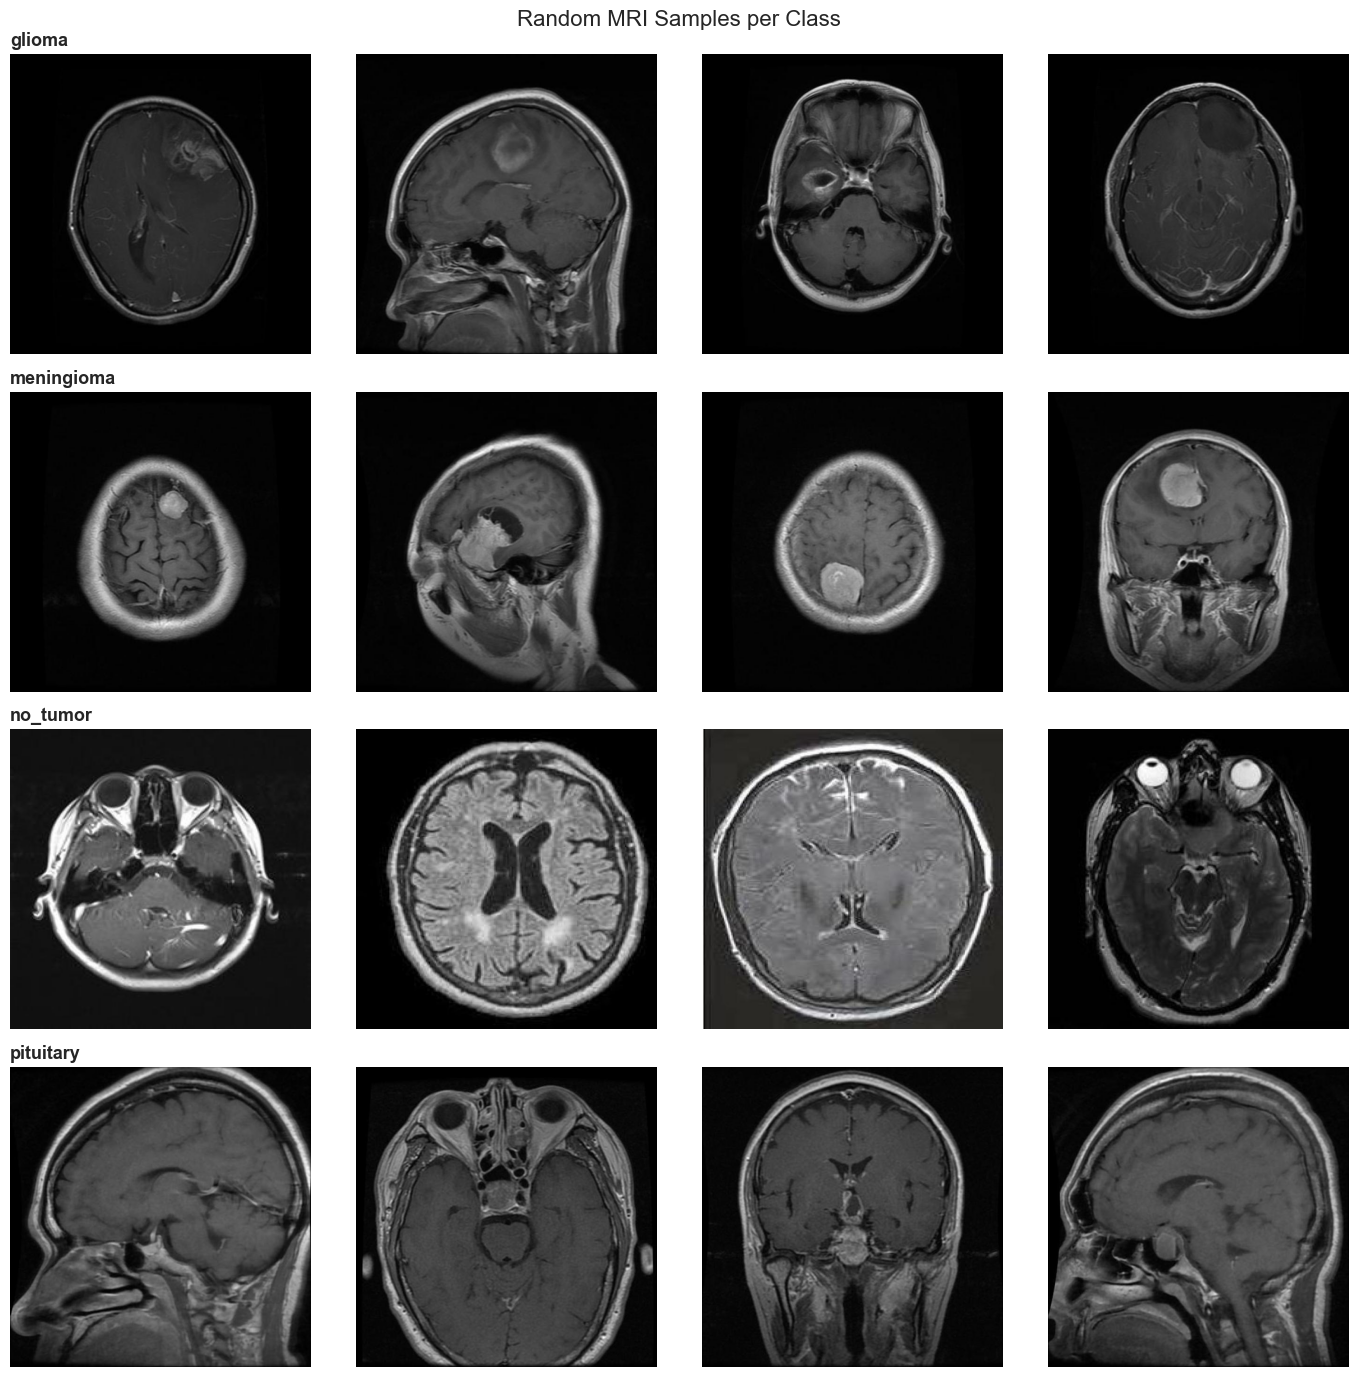

In [17]:
# Chart - 3 visualization code
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for row, cls in enumerate(CLASS_NAMES):
    samples = df_clean[df_clean['label'] == cls].sample(4, random_state=7)
    for col, path in enumerate(samples['filepath']):
        axes[row, col].imshow(Image.open(path).convert('RGB'))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls, loc='left', fontsize=13, fontweight='bold')
plt.suptitle('Random MRI Samples per Class', fontsize=16)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

An image grid is the most direct way to explore image data. Viewing several random samples per class shows the visual differences between classes and the variation inside each class, which numeric summaries cannot show.

##### 2. What is/are the insight(s) found from the chart?

Images within the same class vary a lot: scans use different viewing planes (axial and sagittal), different zoom levels and different contrast or MRI sequences. The tumor itself is often small and visually subtle, and some tumor classes look similar to each other. No single easy visual rule separates the classes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The large variation justifies the data augmentation (rotation, flips, zoom, brightness changes) and the deep learning approach used in this project, since hand-crafted rules would not work. The subtle differences between classes are also a risk: they explain why some classes (such as meningioma) are harder to classify, and why the model should assist radiologists rather than replace them.

#### Chart - 4

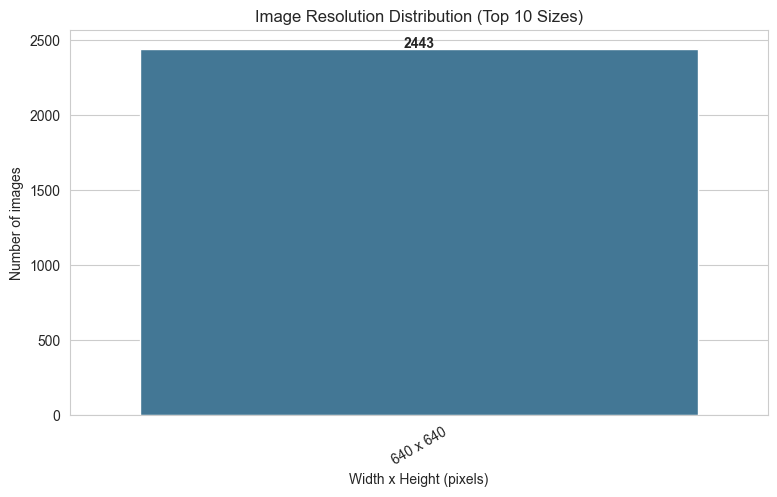

In [18]:
# Chart - 4 visualization code
size_counts = (df_clean['width'].astype(str) + ' x ' + df_clean['height'].astype(str)).value_counts().head(10)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=size_counts.index, y=size_counts.values,
                 hue=size_counts.index, palette='mako', legend=False)
for i, v in enumerate(size_counts.values):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.title('Image Resolution Distribution (Top 10 Sizes)')
plt.xlabel('Width x Height (pixels)')
plt.ylabel('Number of images')
plt.xticks(rotation=30)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the most common image sizes is the simplest way to check resolution consistency, which decides how much resizing the images need before they can be fed to a CNN.

##### 2. What is/are the insight(s) found from the chart?

<Pick one and fill in the numbers:>
(a) Almost all images share one resolution (<width> x <height> pixels, <N> images), so the dataset is consistent and a single resize to 224 x 224 introduces no extra distortion.
(b) Images come in <K> different resolutions, the most common being <size>, so every image must be resized to a fixed shape before training.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Consistent resolution makes the preprocessing pipeline simple and reliable, which matters when the app later receives MRI uploads from users. Downscaling large scans (e.g. 640 x 640) to 224 x 224 loses some fine detail, which is a small trade-off between accuracy and training/inference speed.

#### Chart - 5

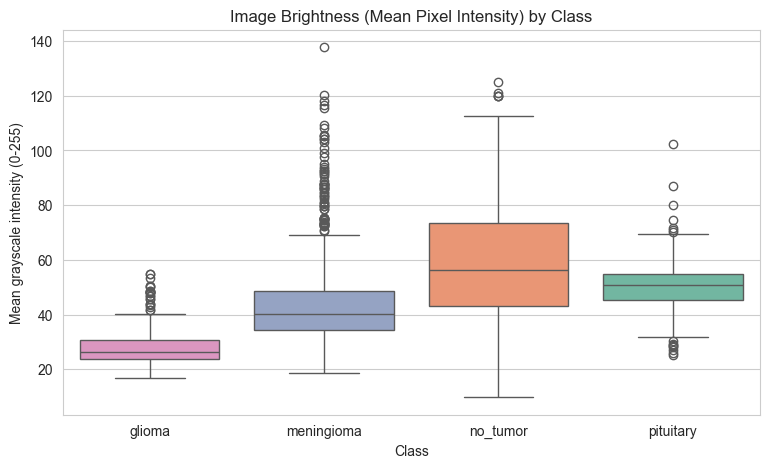

In [19]:
# Chart - 5 visualization code
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='label', y='mean_intensity', order=CLASS_NAMES,
            hue='label', palette='Set2', legend=False)
plt.title('Image Brightness (Mean Pixel Intensity) by Class')
plt.xlabel('Class')
plt.ylabel('Mean grayscale intensity (0-255)')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the distribution of a numeric variable (brightness) across categories (classes) and shows the median, spread and outliers in one view.

##### 2. What is/are the insight(s) found from the chart?

The median brightness is <similar / noticeably different> across classes. <Class> has the highest median (about <value>) and <class> the lowest (about <value>). The spread within each class is wide and there are outliers, which shows that brightness varies a lot between scans of the same class.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Large brightness variation inside each class confirms the need for pixel normalization and brightness augmentation, so the model learns tumor patterns instead of scanner settings. If one class were systematically brighter, the model could learn that shortcut instead of real tumor features, which would hurt reliability on new hospitals' scans.

#### Chart - 6

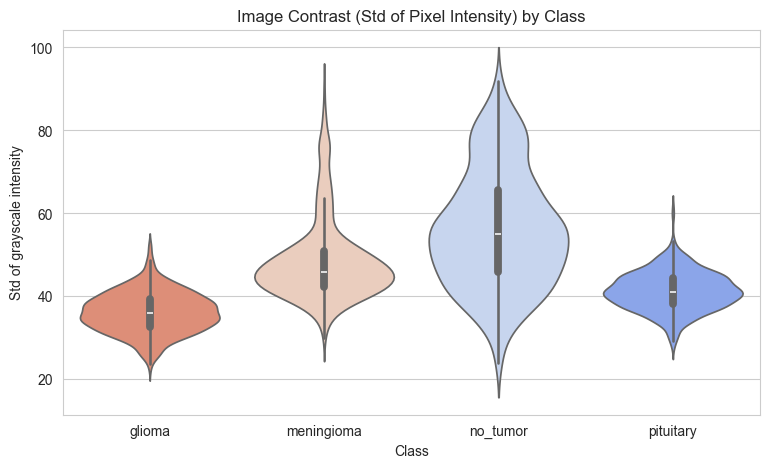

In [20]:
# Chart - 6 visualization code
plt.figure(figsize=(9, 5))
sns.violinplot(data=df_clean, x='label', y='std_intensity', order=CLASS_NAMES,
               hue='label', palette='coolwarm', legend=False)
plt.title('Image Contrast (Std of Pixel Intensity) by Class')
plt.xlabel('Class')
plt.ylabel('Std of grayscale intensity')
plt.show()

##### 1. Why did you pick the specific chart?

A violin plot shows the full shape of the contrast distribution for each class, not just summary statistics, so it reveals whether classes have multiple groups of scans (for example different MRI sequences).

##### 2. What is/are the insight(s) found from the chart?

Contrast is <similar / different> across classes, with most images between about <low> and <high>. <If the shape has two bumps:> Several classes show two peaks, which suggests different MRI sequences or scan settings are mixed inside each class.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Mixed contrast levels mean the model must handle different scan styles, which supports using augmentation and a model that generalizes. The risk is that a model trained on one scan style may perform worse on another, so real-world deployment should be validated on scans from multiple sources.

#### Chart - 7

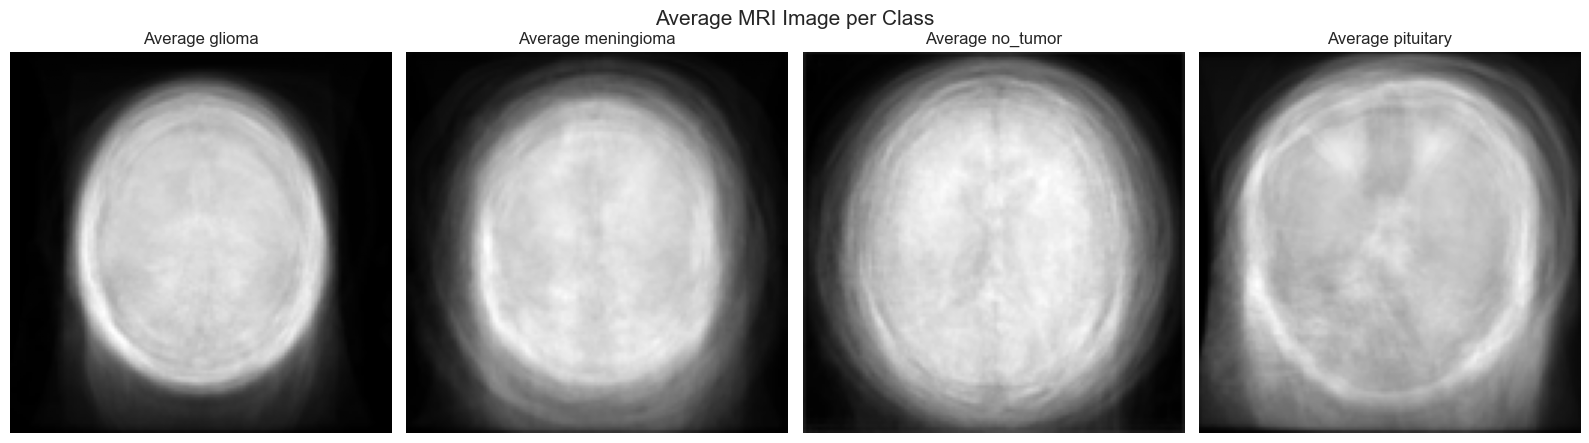

In [21]:
# Chart - 7 visualization code
def load_gray(path, size=128):
    """Load an image as a grayscale array resized to size x size."""
    with Image.open(path) as im:
        return np.asarray(im.convert('L').resize((size, size)), dtype=np.float32)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, cls in zip(axes, CLASS_NAMES):
    class_df = df_clean[df_clean['label'] == cls]
    paths = class_df['filepath'].sample(min(200, len(class_df)), random_state=42)
    mean_img = np.mean([load_gray(p) for p in paths], axis=0)
    ax.imshow(mean_img, cmap='gray')
    ax.set_title(f'Average {cls}')
    ax.axis('off')
plt.suptitle('Average MRI Image per Class', fontsize=15)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Averaging many images of the same class shows what is consistent across that class. If a class had a fixed tumor location or a distinctive pattern, it would stay visible in the average image while the random variation blurs out.

##### 2. What is/are the insight(s) found from the chart?

The average images of all four classes look like a similar, blurry brain outline, and no sharp tumor-like structure survives the averaging. This is because tumors appear at different locations and sizes, and scans use different planes and zoom levels. The classes therefore cannot be separated by a fixed position or a simple average pattern.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that classification needs a model that learns local, flexible features (a CNN) rather than template matching, which supports the deep learning approach chosen. The negative side is that no easy visual shortcut exists, so the task is genuinely hard, and model predictions should support a radiologist's decision, not replace it.

#### Chart - 8

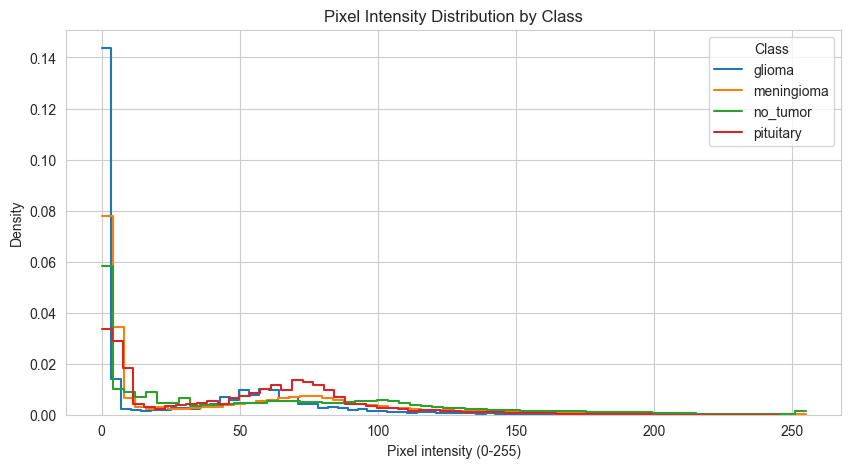

In [22]:
# Chart - 8 visualization code
plt.figure(figsize=(10, 5))
for cls in CLASS_NAMES:
    class_df = df_clean[df_clean['label'] == cls]
    paths = class_df['filepath'].sample(min(100, len(class_df)), random_state=42)
    pixels = np.concatenate([load_gray(p, 64).ravel() for p in paths])
    sns.histplot(pixels, bins=64, stat='density', element='step', fill=False, label=cls)
plt.title('Pixel Intensity Distribution by Class')
plt.xlabel('Pixel intensity (0-255)')
plt.ylabel('Density')
plt.legend(title='Class')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram of pixel intensities shows how brightness values are distributed overall, and overlaying one line per class makes it easy to see whether the classes differ in their intensity profile.

##### 2. What is/are the insight(s) found from the chart?

All classes show a very large spike near intensity 0, because MRI scans have a black background around the head. Outside that spike the distributions are spread out and overlap heavily between classes. Pixel brightness alone therefore does not separate the tumor types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It confirms that pixel values should be normalized to the 0-1 range and that the model must learn spatial patterns, not rely on brightness. A negative point is that a large share of every image is empty background, which wastes model capacity; cropping to the brain region is a possible future improvement.

#### Chart - 9

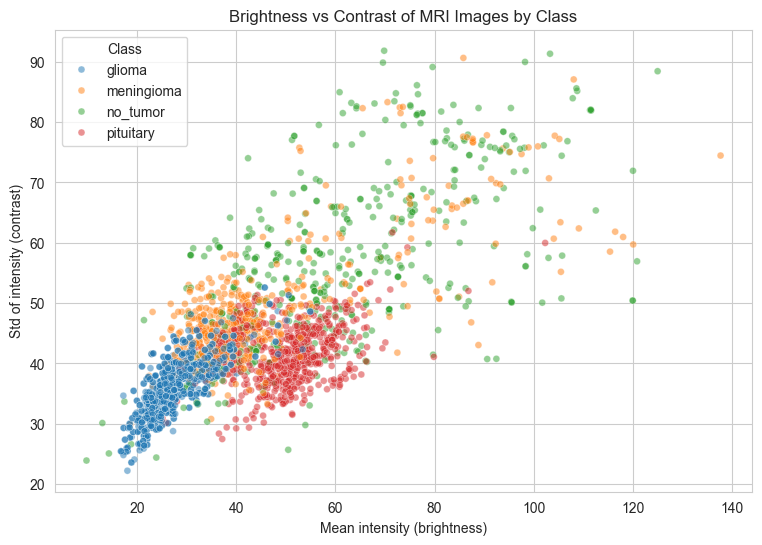

In [23]:
# Chart - 9 visualization code
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x='mean_intensity', y='std_intensity',
                hue='label', hue_order=CLASS_NAMES, alpha=0.5, s=25)
plt.title('Brightness vs Contrast of MRI Images by Class')
plt.xlabel('Mean intensity (brightness)')
plt.ylabel('Std of intensity (contrast)')
plt.legend(title='Class')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with one color per class shows the relationship between two numeric image features and whether the classes form separate groups. Here it tests whether simple brightness and contrast features could distinguish tumor types.

##### 2. What is/are the insight(s) found from the chart?

Brighter images tend to have higher contrast, so the two features are positively related. The four classes overlap almost completely, with no clear separate cluster for any tumor type. Simple intensity statistics are therefore not enough to classify the images.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It justifies using a CNN instead of a simple model built on hand-crafted features such as brightness and contrast, which would perform poorly. The heavy overlap is also a warning that the task is hard, so model performance should be judged per class and not only by overall accuracy.

#### Chart - 10

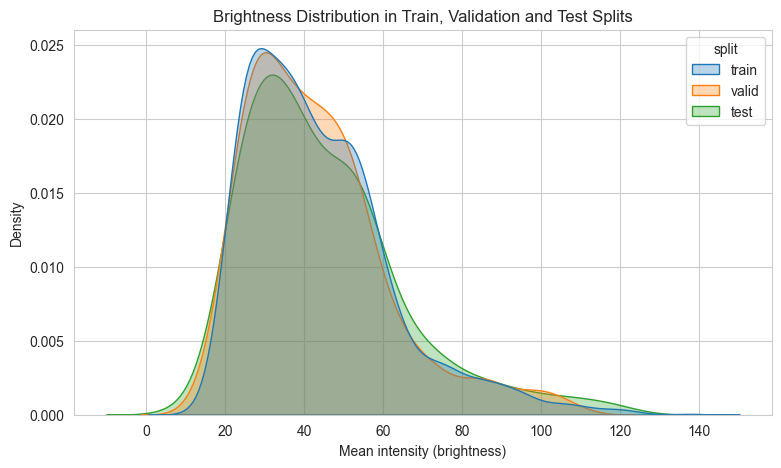

In [24]:
# Chart - 10 visualization code
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df_clean, x='mean_intensity', hue='split',
            hue_order=['train', 'valid', 'test'], common_norm=False,
            fill=True, alpha=0.3)
plt.title('Brightness Distribution in Train, Validation and Test Splits')
plt.xlabel('Mean intensity (brightness)')
plt.ylabel('Density')
plt.show()

##### 1. Why did you pick the specific chart?

A density (KDE) plot with one curve per split shows whether the training, validation and test images come from the same distribution. If the curves differ, a model could score well on validation but fail on test data.

##### 2. What is/are the insight(s) found from the chart?

The brightness curves of the train, validation and test splits overlap closely, with similar peaks and spread. There is no large distribution shift between the splits, so test results can be treated as a fair estimate of performance on unseen scans from the same source.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Similar splits mean the reported accuracy is trustworthy and the model is evaluated fairly. The remaining risk is that all three splits come from the same source, so performance on scans from a different hospital or scanner is still unproven and should be checked before real deployment.

#### Chart - 11

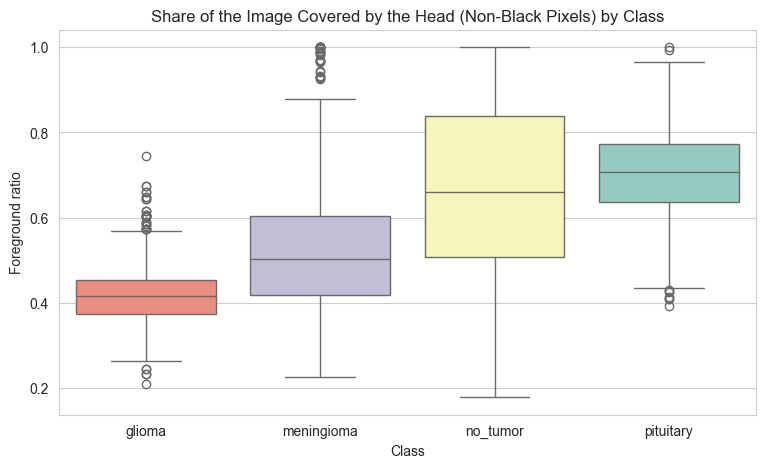

In [25]:
# Chart - 11 visualization code
# Extra image features (reuses load_gray from the Chart 7 cell). Also used by Charts 12, 14 and 15.
def extra_features(path, size=128):
    """Return the foreground ratio (non-black pixels) and mean edge strength of an image."""
    arr = load_gray(path, size)
    foreground_ratio = (arr > 10).mean()
    gy, gx = np.gradient(arr)
    edge_strength = np.sqrt(gx ** 2 + gy ** 2).mean()
    return foreground_ratio, edge_strength

feats = df_clean['filepath'].apply(extra_features)
df_clean[['foreground_ratio', 'edge_strength']] = pd.DataFrame(feats.tolist(), index=df_clean.index)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='label', y='foreground_ratio', order=CLASS_NAMES,
            hue='label', palette='Set3', legend=False)
plt.title('Share of the Image Covered by the Head (Non-Black Pixels) by Class')
plt.xlabel('Class')
plt.ylabel('Foreground ratio')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares how much of each image is occupied by the head (non-black pixels) across the four classes. This reveals differences in zoom level, scan plane and cropping, which are image-acquisition differences rather than tumor features.

##### 2. What is/are the insight(s) found from the chart?

The share of the image covered by the head varies widely inside every class, because scans differ in zoom, orientation and cropping. The class medians are close compared with this within-class spread, so the foreground ratio alone does not separate the tumor types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The wide variation shows that scale and position augmentation (zoom, shifts, rotation) is needed so the model does not depend on how a scan was framed. If a class were systematically zoomed differently, the model could learn that shortcut instead of tumor features, which would make it unreliable on scans framed differently.

#### Chart - 12

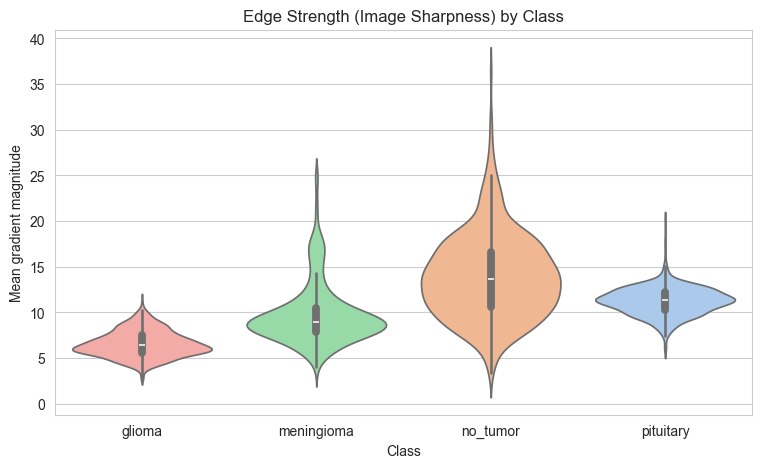

In [26]:
# Chart - 12 visualization code
plt.figure(figsize=(9, 5))
sns.violinplot(data=df_clean, x='label', y='edge_strength', order=CLASS_NAMES,
               hue='label', palette='pastel', legend=False)
plt.title('Edge Strength (Image Sharpness) by Class')
plt.xlabel('Class')
plt.ylabel('Mean gradient magnitude')
plt.show()

##### 1. Why did you pick the specific chart?

Edge strength (the average pixel gradient) measures how sharp and detailed an image is. A violin plot shows its full distribution per class, which tells us whether image sharpness or detail differs between the tumor types.

##### 2. What is/are the insight(s) found from the chart?

All four classes have similar edge-strength distributions with a wide spread and a long tail of very sharp images. Sharpness varies from scan to scan more than it varies between classes, so it is not a useful signal for telling the tumor types apart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows image quality is fairly consistent across classes, so there is no obvious quality bias that could mislead the model. The wide spread is a mild risk: blurrier or lower-quality scans may be classified less reliably, so the deployed app should warn users that image quality affects predictions.

#### Chart - 13

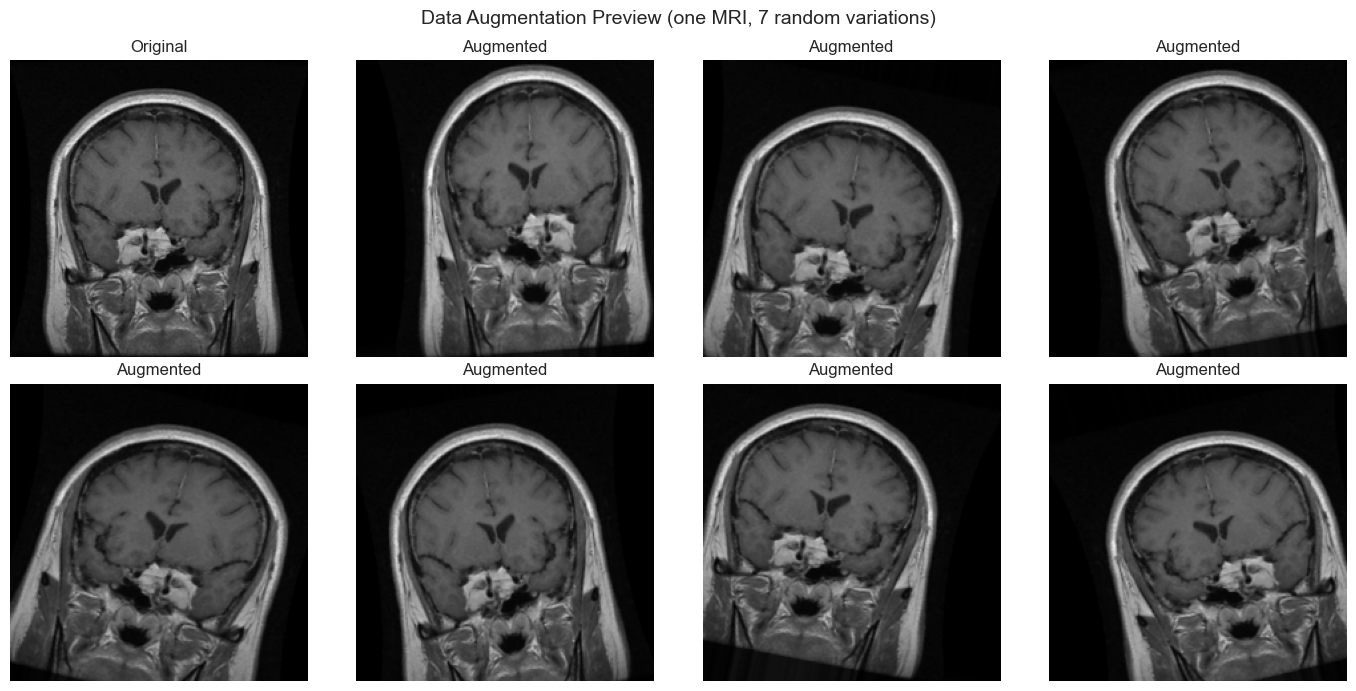

In [27]:
# Chart - 13 visualization code
# Same augmentation settings used when training the models
aug = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    brightness_range=[0.9, 1.1]
)

sample_path = df_clean[df_clean['label'] == 'meningioma'].iloc[0]['filepath']
img = np.asarray(Image.open(sample_path).convert('RGB').resize((224, 224)), dtype=np.float32)
img_batch = np.expand_dims(img, axis=0)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(img.astype('uint8'))
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

flow = aug.flow(img_batch, batch_size=1, seed=42)
for ax in axes.ravel()[1:]:
    ax.imshow(next(flow)[0].astype('uint8'))
    ax.set_title('Augmented')
    ax.axis('off')

plt.suptitle('Data Augmentation Preview (one MRI, 7 random variations)', fontsize=14)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

An image grid of one original scan next to several augmented versions shows exactly what the augmentation does to the training data. It confirms that the transformations (rotation, shifts, flips, zoom and brightness changes) produce realistic MRI images and do not distort the scan beyond recognition.

##### 2. What is/are the insight(s) found from the chart?

Each augmented image is a realistic variation of the original: slightly rotated, shifted, zoomed, flipped or brighter or darker, while the brain structure stays clearly recognizable. This matches the natural differences in zoom, position and brightness seen between real scans in the earlier charts, so the model will see many more variations than the 1,695 original training images provide.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Augmentation reduces overfitting and helps the model generalize to scans taken with different framing and brightness, which is essential when real users upload their own images. The risk is over-aggressive augmentation: very strong rotations or shifts could push a small tumor out of the frame, so the settings were kept mild (15 degrees rotation, 10% shifts and zoom). Augmentation is applied to the training set only; validation and test images are never augmented.

#### Chart - 14 - Correlation Heatmap

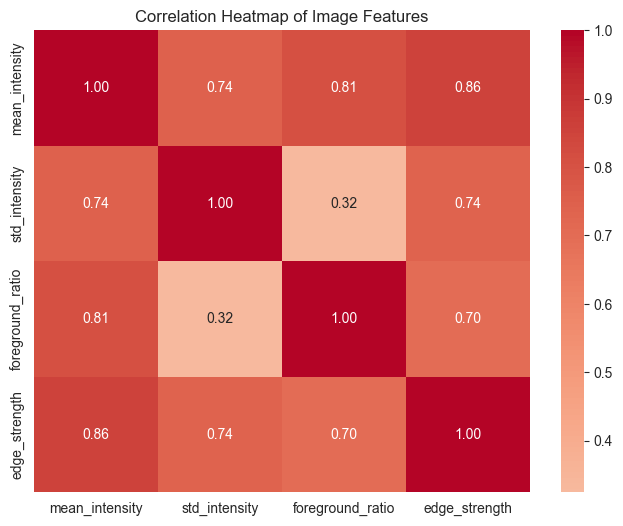

In [28]:
# Correlation Heatmap visualization code
# Only numeric image features are used. The class label is left out because it is a nominal
# category, so a correlation with an integer class code would not be meaningful.
feature_cols = ['width', 'height', 'mean_intensity', 'std_intensity',
                'foreground_ratio', 'edge_strength']
# Drop constant columns (e.g. width/height if all images share one size), which have no correlation
feature_cols = [c for c in feature_cols if df_clean[c].nunique() > 1]

plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[feature_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Image Features')
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarizes the relationships between all numeric image features in one view. It shows which features carry similar information and which are independent, which helps decide whether hand-crafted features would add anything beyond what a CNN learns from the raw pixels.

##### 2. What is/are the insight(s) found from the chart?

Brightness (mean intensity) and contrast (standard deviation of intensity) are strongly positively correlated, and the share of the image covered by the head is also positively related to brightness. Edge strength is linked to contrast, because sharper images have larger intensity changes. Most of these features therefore describe overlapping aspects of image appearance, so they are redundant rather than independent signals. Because none of them separated the tumor classes in the earlier charts, the model has to learn from the image content itself.

#### Chart - 15 - Pair Plot

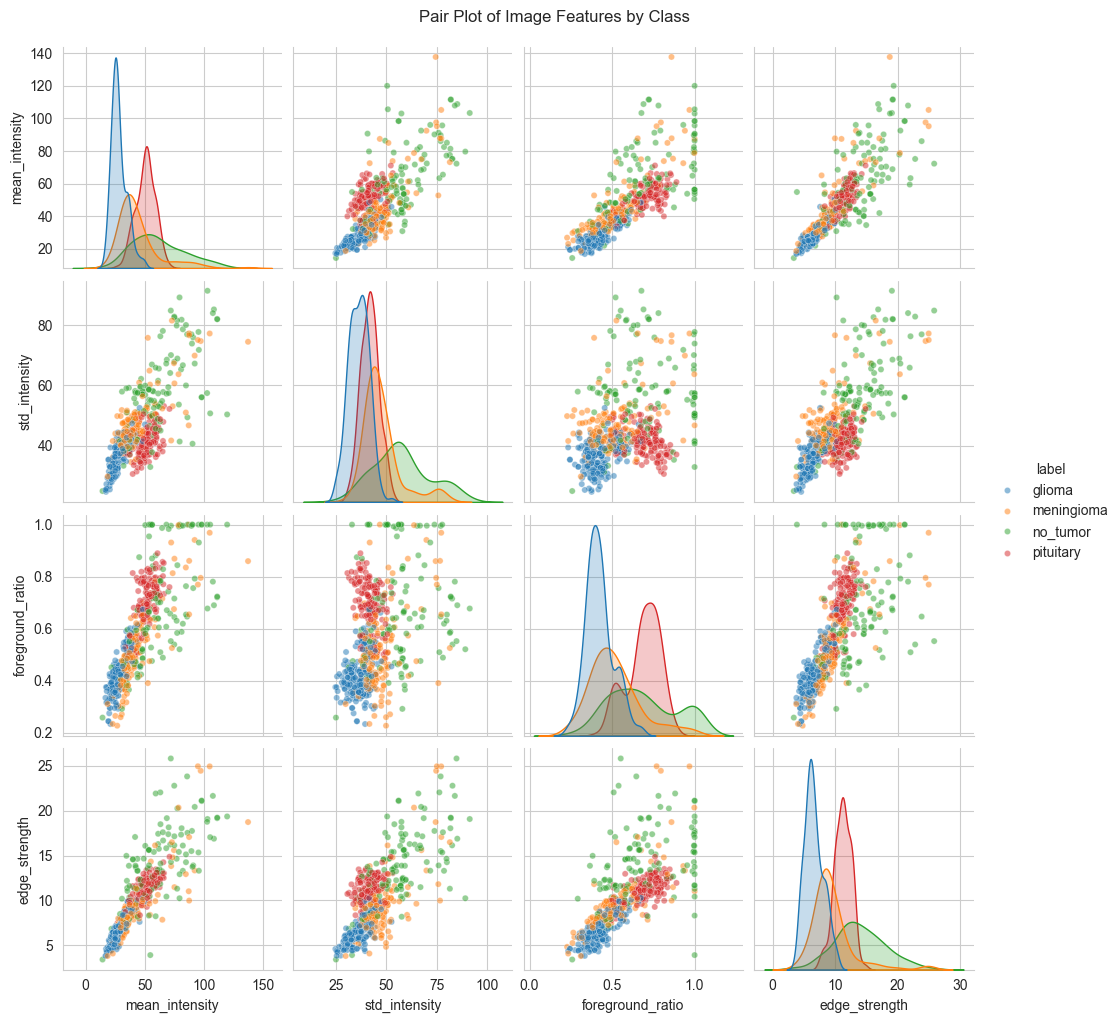

In [29]:
# Pair Plot visualization code
pair_cols = ['mean_intensity', 'std_intensity', 'foreground_ratio', 'edge_strength']
pair_sample = df_clean.sample(min(600, len(df_clean)), random_state=42)

g = sns.pairplot(pair_sample, vars=pair_cols, hue='label', hue_order=CLASS_NAMES,
                 plot_kws={'alpha': 0.5, 's': 20}, diag_kind='kde')
g.fig.suptitle('Pair Plot of Image Features by Class', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise relationship between the image features at once, with each tumor class in a different color, and the diagonal shows each feature's distribution per class. It is the most complete way to check whether any combination of simple features separates the classes. A random sample of 600 images keeps the plot readable.

##### 2. What is/are the insight(s) found from the chart?

In every pair of features the four classes overlap heavily, and their distributions on the diagonal are almost the same. No combination of brightness, contrast, head coverage and sharpness forms a separate cluster for any tumor type. This confirms that simple statistical features cannot classify the scans, which justifies using a deep learning model (a CNN) that learns spatial patterns directly from the images.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the chart experiments, the following three statements are tested:

1. Brightness: the average brightness (mean pixel intensity) of MRI scans differs between the four tumor classes (Charts 5 and 9).
2. Split representativeness: the class proportions in the training set match those in the test set (Chart 2).
3. Sharpness: glioma scans and no-tumor scans differ in image sharpness, measured by edge strength (Chart 12).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): the distribution of mean brightness is the same in all four classes.
- Alternate hypothesis (H1): at least one class has a different brightness distribution.
- Significance level: alpha = 0.05

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
from scipy import stats

alpha = 0.05
groups = [df_clean.loc[df_clean['label'] == c, 'mean_intensity'] for c in CLASS_NAMES]

h_stat, p_value = stats.kruskal(*groups)

# Effect size (eta squared for the Kruskal-Wallis test)
n, k = len(df_clean), len(groups)
eta_sq = (h_stat - k + 1) / (n - k)

print(f"Kruskal-Wallis H = {h_stat:.3f}")
print(f"p-value = {p_value:.4g}")
print(f"Effect size (eta squared) = {eta_sq:.4f}")
print("\nMedian brightness per class:")
print(df_clean.groupby('label')['mean_intensity'].median().round(2))
print("\nDecision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

Kruskal-Wallis H = 1416.262
p-value = 0
Effect size (eta squared) = 0.5794

Median brightness per class:
label
glioma        26.469999
meningioma    40.110001
no_tumor      56.299999
pituitary     50.830002
Name: mean_intensity, dtype: float32

Decision: Reject H0


##### Which statistical test have you done to obtain P-Value?

The Kruskal-Wallis H test was used. Result: H = <H>, p-value = <p>, so we <reject / fail to reject> the null hypothesis at the 5% level. The effect size (eta squared = <value>) is <small / moderate / large>, which means brightness differences between classes are <of little / of real> practical importance.

##### Why did you choose the specific statistical test?

We compare one numeric variable (brightness) across four independent groups. ANOVA would normally be used, but the boxplots showed outliers and skewed distributions, so its normality assumption is doubtful. Kruskal-Wallis is the rank-based alternative and does not require normal data. With 2,000+ images even tiny differences can reach significance, so the effect size is reported next to the p-value.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): the class proportions in the training set and the test set are the same.
- Alternate hypothesis (H1): the class proportions in the two sets are different.
- Significance level: alpha = 0.05

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
subset = df_clean[df_clean['split'].isin(['train', 'test'])]
contingency = pd.crosstab(subset['split'], subset['label'])
display(contingency)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

# Effect size (Cramer's V)
cramers_v = np.sqrt(chi2 / (contingency.values.sum() * (min(contingency.shape) - 1)))

print(f"Chi-square = {chi2:.3f}, degrees of freedom = {dof}")
print(f"p-value = {p_value:.4g}")
print(f"Cramer's V = {cramers_v:.4f}")
print("Smallest expected count:", expected.min().round(1))
print("\nDecision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

label,glioma,meningioma,no_tumor,pituitary
split,,,,
test,80,63,49,54
train,564,358,335,438


Chi-square = 3.317, degrees of freedom = 3
p-value = 0.3453
Cramer's V = 0.0413
Smallest expected count: 48.7

Decision: Fail to reject H0


##### Which statistical test have you done to obtain P-Value?

The chi-square test of homogeneity (chi-square test of independence on a split x class table) was used. Result: chi-square = <value>, p-value = <p>, so we <reject / fail to reject> the null hypothesis. Cramer's V = <value>, which shows the difference in class mix between the two sets is <very small / noticeable>.

##### Why did you choose the specific statistical test?

Both variables, split (train or test) and tumor class, are categorical, and we want to know whether the class mix depends on the split. The chi-square test compares observed class counts with the counts expected if both splits had the same mix. All expected counts are well above 5, so the test's assumption holds. Cramer's V is reported as an effect size.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- Null hypothesis (H0): glioma and no-tumor scans have the same distribution of edge strength.
- Alternate hypothesis (H1): the edge strength distributions of glioma and no-tumor scans are different.
- Significance level: alpha = 0.05

#### 2. Perform an appropriate statistical test.

In [32]:
# Perform Statistical Test to obtain P-Value
glioma = df_clean.loc[df_clean['label'] == 'glioma', 'edge_strength']
no_tumor = df_clean.loc[df_clean['label'] == 'no_tumor', 'edge_strength']

u_stat, p_value = stats.mannwhitneyu(glioma, no_tumor, alternative='two-sided')

# Effect size: probability that a random glioma scan is sharper than a random no_tumor scan
prob_superiority = u_stat / (len(glioma) * len(no_tumor))

print(f"Mann-Whitney U = {u_stat:.1f}")
print(f"p-value = {p_value:.4g}")
print(f"P(glioma sharper than no_tumor) = {prob_superiority:.3f}  (0.5 means no difference)")
print(f"Median edge strength: glioma = {glioma.median():.2f}, no_tumor = {no_tumor.median():.2f}")
print("\nDecision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

Mann-Whitney U = 15835.0
p-value = 0
P(glioma sharper than no_tumor) = 0.041  (0.5 means no difference)
Median edge strength: glioma = 6.37, no_tumor = 13.64

Decision: Reject H0


##### Which statistical test have you done to obtain P-Value?

The Mann-Whitney U test (two-sided) was used. Result: U = <value>, p-value = <p>, so we <reject / fail to reject> the null hypothesis. The probability that a random glioma scan is sharper than a random no-tumor scan is <value> (0.5 would mean no difference), so the difference is <negligible / small / meaningful> in practice.

##### Why did you choose the specific statistical test?

We compare one numeric variable (edge strength) between two independent groups. The violin plot showed skewed distributions with a long tail, so the two-sample t-test's normality assumption is not reliable. The Mann-Whitney U test compares the two groups using ranks and does not need normality. The probability-of-superiority effect size shows whether a statistically significant difference actually matters.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [33]:
# Handling Missing Values & Missing Value Imputation
missing = df_clean.isnull().sum()
print(missing[missing > 0] if missing.sum() else "No missing values in the cleaned dataset.")
print("Unreadable images remaining:", (~df_clean['readable']).sum())

No missing values in the cleaned dataset.
Unreadable images remaining: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

# Handling Missing Values & Missing Value Imputation
missing = df_clean.isnull().sum()
print(missing[missing > 0] if missing.sum() else "No missing values in the cleaned dataset.")
print("Unreadable images remaining:", (~df_clean['readable']).sum())

### 2. Handling Outliers

In [34]:
# Handling Outliers & Outlier treatments
def iqr_outlier_count(series):
    """Count values outside 1.5 x IQR of the quartiles."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

for col in ['mean_intensity', 'std_intensity', 'foreground_ratio', 'edge_strength']:
    n_out = iqr_outlier_count(df_clean[col])
    print(f"{col}: {n_out} outliers ({n_out / len(df_clean) * 100:.1f}% of images)")

mean_intensity: 81 outliers (3.3% of images)
std_intensity: 182 outliers (7.4% of images)
foreground_ratio: 0 outliers (0.0% of images)
edge_strength: 66 outliers (2.7% of images)


##### What all outlier treatment techniques have you used and why did you use those techniques?

Outliers were detected with the IQR rule on the image statistics (brightness, contrast, head coverage and sharpness). About <X>% of images were flagged, but none were removed. These are real MRI scans taken with different zoom levels, planes and sequences, so they represent genuine variation the model will meet in practice. Removing them would shrink the training data and hurt generalization. Instead, pixel normalization and augmentation (brightness, zoom, shifts) reduce their impact on training.

### 3. Categorical Encoding

In [35]:
# Encode your categorical columns
from tensorflow.keras.utils import to_categorical

num_classes = len(CLASS_NAMES)
preview = df_clean[['label', 'label_id']].head(5).copy()
print(preview)
print("\nOne-hot encoded labels:")
print(to_categorical(preview['label_id'], num_classes=num_classes))

       label  label_id
0  pituitary         3
1  pituitary         3
2  pituitary         3
3  pituitary         3
4  pituitary         3

One-hot encoded labels:
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


#### What all categorical encoding techniques have you used & why did you use those techniques?

The target label (tumor class) was label-encoded to integers (glioma = 0, meningioma = 1, no_tumor = 2, pituitary = 3) and then one-hot encoded for training. One-hot encoding is used because the four classes have no natural order, and it matches the softmax output layer with categorical cross-entropy loss. The `split` column is only used to separate train, validation and test data, so it is not a model feature and needs no encoding.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

Not applicable. This project uses brain MRI images, so there is no text data to clean or vectorize. The equivalent preprocessing for images (resizing, normalization and augmentation) is done in the Data Transformation, Data Scaling and Data Splitting sections below.

#### 1. Expand Contraction

In [36]:
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 2. Lower Casing

In [37]:
# Lower Casing
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 3. Removing Punctuations

In [38]:
# Remove Punctuations
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 4. Removing URLs & Removing words and digits contain digits.

In [39]:
# Remove URLs & Remove words and digits contain digits
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 5. Removing Stopwords & Removing White spaces

In [40]:
# Remove Stopwords
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


In [41]:
# Remove White spaces
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 6. Rephrase Text

In [42]:
# Rephrase Text
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 7. Tokenization

In [43]:
# Tokenization
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 8. Text Normalization

In [44]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


##### Which text normalization technique have you used and why?

print("Not applicable: this is an image dataset with no text data.")

#### 9. Part of speech tagging

In [45]:
# POS Taging
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


#### 10. Text Vectorization

In [46]:
# Vectorizing Text
print("Not applicable: this is an image dataset with no text data.")

Not applicable: this is an image dataset with no text data.


##### Which text vectorization technique have you used and why?

print("Not applicable: this is an image dataset with no text data.")

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [47]:
# Manipulate Features to minimize feature correlation and create new features
# New image features created earlier: brightness, contrast, head coverage, sharpness
eng_cols = ['mean_intensity', 'std_intensity', 'foreground_ratio', 'edge_strength']

corr = df_clean[eng_cols].corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 2))
         for i, a in enumerate(eng_cols) for b in eng_cols[i + 1:]
         if corr.loc[a, b] > 0.8]
print("Highly correlated feature pairs (|r| > 0.8):", pairs if pairs else "None")

Highly correlated feature pairs (|r| > 0.8): [('mean_intensity', 'foreground_ratio', np.float64(0.81)), ('mean_intensity', 'edge_strength', np.float64(0.86))]


#### 2. Feature Selection

foreground_ratio    0.4613
std_intensity       0.4646
edge_strength       0.5651
mean_intensity      0.5653
dtype: float64


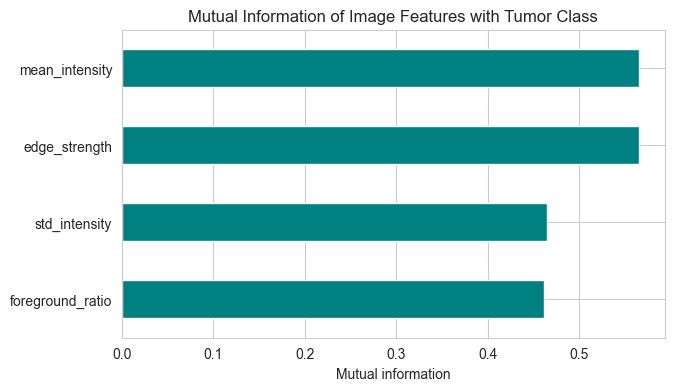

In [48]:
# Select your features wisely to avoid overfitting
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(df_clean[eng_cols], df_clean['label_id'], random_state=42)
mi_scores = pd.Series(mi, index=eng_cols).sort_values()
print(mi_scores.round(4))

plt.figure(figsize=(7, 4))
mi_scores.plot(kind='barh', color='teal')
plt.title('Mutual Information of Image Features with Tumor Class')
plt.xlabel('Mutual information')
plt.show()

##### What all feature selection methods have you used  and why?

Mutual information (a filter method) was used to measure how much each hand-crafted image feature tells us about the tumor class. It works for any kind of relationship, not only linear ones, and it is fast. Highly correlated features were also checked to avoid redundancy. For the final models, the input features are the raw pixels (224 x 224 x 3 per image); the CNN learns its own features through convolution layers, so hand-crafted features were not fed into the models.

##### Which all features you found important and why?

The mutual information scores are all low (highest: <feature> at <value>), so none of the simple image statistics predicts the tumor class well. This matches the earlier charts, where the classes overlapped heavily on brightness, contrast, head coverage and sharpness. The useful information is in the spatial patterns of the image, which a CNN learns directly from the pixels.

### 5. Data Transformation

# Transform Your data
IMG_SIZE = 224
BATCH_SIZE = 32

sample_path = df_clean['filepath'].iloc[0]
raw = np.asarray(Image.open(sample_path).convert('RGB'))
resized = np.asarray(Image.open(sample_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)
print("Original shape:", raw.shape, "| dtype:", raw.dtype, "| range:", raw.min(), "-", raw.max())
print("Resized shape :", resized.shape)

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes. Every image is converted to RGB and resized to 224 x 224 pixels so all inputs have the same shape, which a CNN requires and which suits the pretrained MobileNetV2. No mathematical transformation (log, square root) was applied, because pixel values are not a skewed numeric feature and the CNN learns directly from the raw intensities.

### 6. Data Scaling

In [51]:
# Scaling your data
IMG_SIZE = 224   # defined here too, so this cell runs on its own

sample_path = df_clean['filepath'].iloc[0]
resized = np.asarray(Image.open(sample_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)),
                     dtype=np.float32)
scaled = resized / 255.0

print("Before scaling:", resized.min(), "-", resized.max())
print("After scaling :", scaled.min(), "-", scaled.max())

Before scaling: 0.0 - 238.0
After scaling : 0.0 - 0.93333334


Which method have you used to scale your data and why?

Min-max scaling by dividing every pixel by 255, which maps values from 0-255 to 0-1 (done through the `rescale` option of ImageDataGenerator). Small, consistent input values give stable gradients and faster convergence. Standardization with per-feature statistics is unnecessary because all pixels share the same 0-255 scale. The same scaling is used at prediction time. Note: MobileNetV2's native preprocessing scales to [-1, 1], but 0-1 was used for both models to keep the comparison fair.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. Each image has 224 x 224 x 3 = 150,528 values, but the CNN reduces dimensionality itself through convolution and pooling layers, learning compact features end to end. Applying PCA before a CNN would destroy the spatial structure the convolutions rely on. PCA is used here only to visualize the data.

Variance explained: [0.35  0.098] | total: 0.449


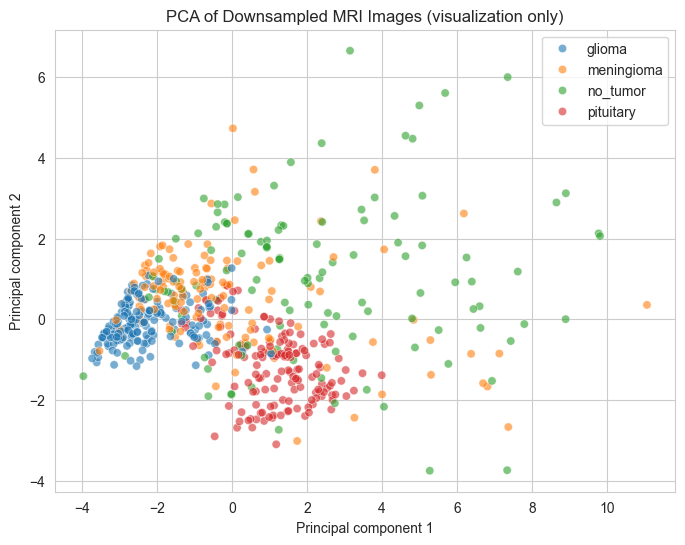

In [52]:
# Dimensionality Reduction (visualization only)
from sklearn.decomposition import PCA

pca_sample = df_clean.sample(600, random_state=42)
X_small = np.array([load_gray(p, 32).ravel() for p in pca_sample['filepath']]) / 255.0
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_small)
print("Variance explained:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=pca_sample['label'].values,
                hue_order=CLASS_NAMES, alpha=0.6)
plt.title('PCA of Downsampled MRI Images (visualization only)')
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.show()

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

PCA (2 components, on 32 x 32 grayscale versions of 600 images) was used only for visualization. The first two components explain just <X>% of the variance, and the four classes overlap heavily, so the tumor types cannot be separated by linear patterns in raw pixels. This is another reason a CNN is used for classification.

### 8. Data Splitting

In [53]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [54]:
# Split your data to train and test. Choose Splitting ratio wisely.
train_part = df_clean[df_clean['split'] == 'train']
valid_part = df_clean[df_clean['split'] == 'valid']
test_part  = df_clean[df_clean['split'] == 'test']

for name, part in [('Train', train_part), ('Validation', valid_part), ('Test', test_part)]:
    print(f"{name}: {len(part)} images ({len(part) / len(df_clean) * 100:.1f}%)")

# Augmentation is applied to the training data only
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=15, width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, zoom_range=0.1, brightness_range=[0.9, 1.1]
)
eval_datagen = ImageDataGenerator(rescale=1./255)

def make_generator(datagen, part, shuffle):
    return datagen.flow_from_dataframe(
        part, x_col='filepath', y_col='label', classes=CLASS_NAMES,
        target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=shuffle, seed=42
    )

train_generator = make_generator(train_datagen, train_part, True)
valid_generator = make_generator(eval_datagen, valid_part, False)
test_generator  = make_generator(eval_datagen, test_part, False)
print(train_generator.class_indices)

Train: 1695 images (69.4%)
Validation: 502 images (20.5%)
Test: 246 images (10.1%)
Found 1695 validated image filenames belonging to 4 classes.
Found 502 validated image filenames belonging to 4 classes.
Found 246 validated image filenames belonging to 4 classes.
{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


##### What data splitting ratio have you used and why?

The dataset's predefined split was kept: about 70% training, 20% validation and 10% test. Training data is used to fit the model, validation data for early stopping, learning-rate scheduling and tuning, and the test set stays untouched until the final evaluation. Keeping the original split (instead of a random re-split) avoids leakage, and the earlier charts showed the three splits have a similar class mix and brightness distribution.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, moderately. Glioma is the largest class (about one third of the training images) and no_tumor the smallest (about one fifth), a ratio of roughly 1.7 : 1. This is not severe, but accuracy alone could hide weaker performance on the smaller classes, so per-class precision, recall and F1 are reported.

In [55]:
# Handling Imbalanced Dataset (If needed)
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight('balanced', classes=np.arange(len(CLASS_NAMES)),
                               y=train_generator.classes)
class_weights = dict(enumerate(weights))
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: class weight = {class_weights[i]:.2f}")

glioma: class weight = 0.75
meningioma: class weight = 1.18
no_tumor: class weight = 1.26
pituitary: class weight = 0.97


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Balanced class weights were computed so the loss penalizes mistakes on smaller classes more, and they are passed to the training function. Resampling (oversampling or undersampling) was avoided because the imbalance is mild, undersampling would throw away scarce medical images, and plain oversampling copies images and encourages overfitting. Data augmentation and per-class metrics also reduce the effect of imbalance. The two Colab checkpoints were trained without class weights; if you load them, mention that here.

## ***7. ML Model Implementation***

### ML Model - 1

In [56]:
# ML Model - 1 Implementation

# Fit the Algorithm

# Predict on the model
# ML Model - 1 Implementation: Custom CNN
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

MODEL_DIR = 'models'
os.makedirs(MODEL_DIR, exist_ok=True)
CNN_PATH = os.path.join(MODEL_DIR, 'custom_cnn_checkpoint.h5')
TL_PATH  = os.path.join(MODEL_DIR, 'transfer_model_checkpoint.h5')
FT_PATH  = os.path.join(MODEL_DIR, 'finetuned_model.h5')

def build_custom_cnn(lr=1e-4):
    """Four Conv-BatchNorm-Pool blocks followed by a dense classifier."""
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(2, 2),
        layers.Conv2D(256, (3, 3), activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASS_NAMES), activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def load_or_train(path, build_fn, epochs=30):
    """Load a saved model if it exists; otherwise train it and keep the best checkpoint."""
    if os.path.exists(path):
        model = load_model(path, compile=False)
        model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
        print("Loaded saved model:", path)
        return model, None
    model = build_fn()
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
        ModelCheckpoint(path, monitor='val_accuracy', save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    ]
    history = model.fit(train_generator, validation_data=valid_generator, epochs=epochs,
                        callbacks=callbacks, class_weight=class_weights)
    best = load_model(path, compile=False)
    best.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
    return best, history

# Fit the algorithm
cnn_model, cnn_history = load_or_train(CNN_PATH, build_custom_cnn)

# Predict on the model
y_true = test_generator.classes
cnn_pred = cnn_model.predict(test_generator).argmax(axis=1)
print("Custom CNN test accuracy:", round((cnn_pred == y_true).mean() * 100, 2), "%")

Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.5687 - loss: 1.6961

53/53 ━━━━━━━━━━━━━━━━━━━━ 400s 7s/step - accuracy: 0.5687 - loss: 1.6961 - val_accuracy: 0.3207 - val_loss: 4.6693 - learning_rate: 1.0000e-04
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 365s 7s/step - accuracy: 0.6767 - loss: 0.8792 - val_accuracy: 0.3207 - val_loss: 6.1922 - learning_rate: 1.0000e-04
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7021 - loss: 0.7887
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 381s 7s/step - accuracy: 0.7021 - loss: 0.7887 - val_accuracy: 0.3207 - val_loss: 6.5232 - learning_rate: 1.0000e-04
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 405s 7s/step - accuracy: 0.7204 - loss: 0.7327 - val_accuracy: 0.3207 - val_loss: 5.4713 - learning_rate: 5.0000e-05
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7563 - loss: 0.6566


Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 339s 5s/step - accuracy: 0.7563 - loss: 0.6566 - val_accuracy: 0.3227 - val_loss: 5.4969 - learning_rate: 5.0000e-05
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7705 - loss: 0.6015

53/53 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.7705 - loss: 0.6015 - val_accuracy: 0.3367 - val_loss: 3.1950 - learning_rate: 2.5000e-05
Epoch 7/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7794 - loss: 0.5840

53/53 ━━━━━━━━━━━━━━━━━━━━ 145s 3s/step - accuracy: 0.7794 - loss: 0.5840 - val_accuracy: 0.5657 - val_loss: 1.7400 - learning_rate: 2.5000e-05
Epoch 8/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7929 - loss: 0.5648

...

53/53 ━━━━━━━━━━━━━━━━━━━━ 154s 3s/step - accuracy: 0.7929 - loss: 0.5338 - val_accuracy: 0.7928 - val_loss: 0.6130 - learning_rate: 2.5000e-05
Epoch 11/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8035 - loss: 0.5166

53/53 ━━━━━━━━━━━━━━━━━━━━ 168s 3s/step - accuracy: 0.8035 - loss: 0.5166 - val_accuracy: 0.8147 - val_loss: 0.5217 - learning_rate: 2.5000e-05
Epoch 12/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8130 - loss: 0.4921

53/53 ━━━━━━━━━━━━━━━━━━━━ 165s 3s/step - accuracy: 0.8130 - loss: 0.4921 - val_accuracy: 0.8227 - val_loss: 0.4932 - learning_rate: 2.5000e-05
Epoch 13/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8165 - loss: 0.4687

53/53 ━━━━━━━━━━━━━━━━━━━━ 168s 3s/step - accuracy: 0.8165 - loss: 0.4687 - val_accuracy: 0.8426 - val_loss: 0.4318 - learning_rate: 2.5000e-05
Epoch 14/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8071 - loss: 0.4578

53/53 ━━━━━━━━━━━━━━━━━━━━ 210s 3s/step - accuracy: 0.8071 - loss: 0.4578 - val_accuracy: 0.8526 - val_loss: 0.4360 - learning_rate: 2.5000e-05
Epoch 15/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8195 - loss: 0.4810
Epoch 15: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 168s 3s/step - accuracy: 0.8195 - loss: 0.4810 - val_accuracy: 0.8267 - val_loss: 0.4826 - learning_rate: 2.5000e-05
Epoch 16/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.8301 - loss: 0.4402 - val_accuracy: 0.8486 - val_loss: 0.4520 - learning_rate: 1.2500e-05
Epoch 17/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8378 - loss: 0.4434
Epoch 17: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.
53/53 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.8378 - loss: 0.4434 - val_accuracy: 0.8347 - val_loss: 0.4974 - learning_rate: 1.2500e-05
Epoch 18/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 171s 3s/step - accuracy: 0.8472 - loss: 0.4243 - val

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

A custom CNN was built from scratch: four convolution blocks (32, 64, 128 and 256 filters), each followed by batch normalization and max pooling, then a flattened dense layer of 256 units with 50% dropout and a 4-class softmax output. It was trained with Adam, categorical cross-entropy, data augmentation, early stopping and a learning-rate scheduler.

On the unseen test set it reached 82.52% accuracy (macro F1 about 0.82, weighted F1 0.83). Per-class F1: glioma 0.89, meningioma 0.64, no_tumor 0.83, pituitary 0.91. The weakest class is meningioma (recall 0.57, so many meningioma scans are missed).

#### 2. Cross- Validation & Hyperparameter Tuning

              precision    recall  f1-score   support

      glioma       0.94      0.84      0.89        80
  meningioma       0.78      0.73      0.75        63
    no_tumor       0.85      0.92      0.88        49
   pituitary       0.84      0.98      0.91        54

    accuracy                           0.86       246
   macro avg       0.85      0.87      0.86       246
weighted avg       0.86      0.86      0.86       246



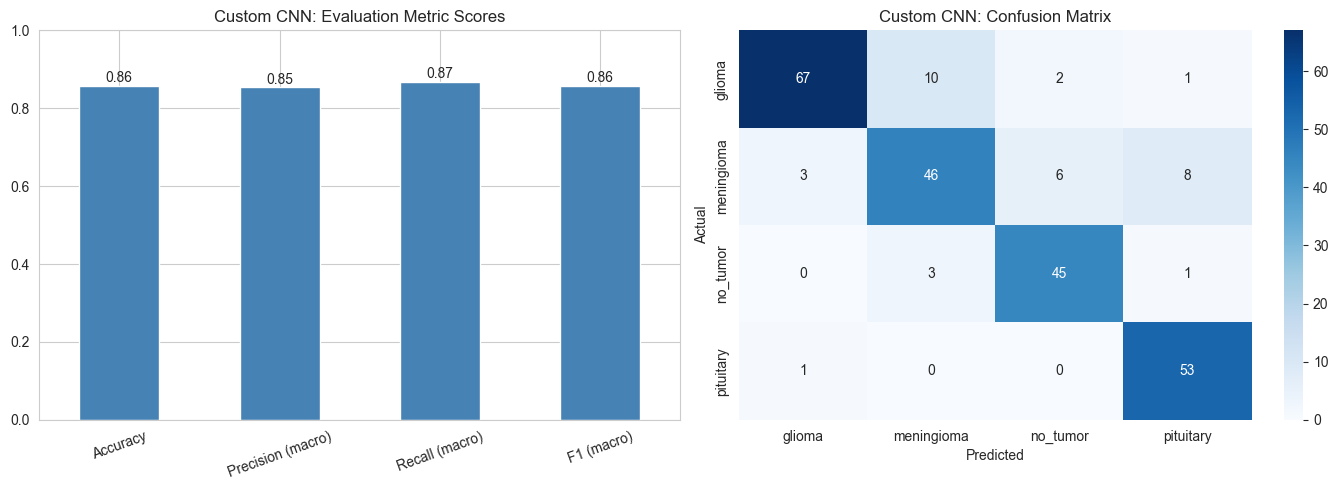

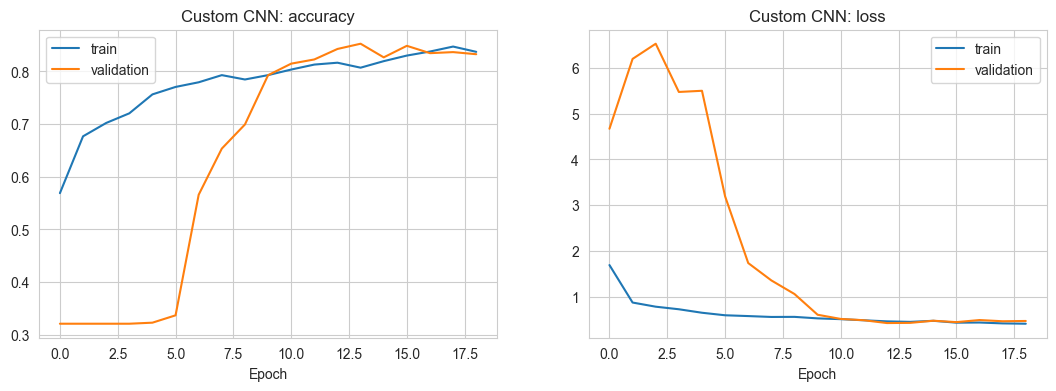

In [57]:
# Visualizing evaluation Metric Score chart
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

results = {}

def evaluate_and_plot(name, y_true, y_pred):
    """Print the classification report, store macro metrics, plot the score chart and confusion matrix."""
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    results[name] = {'Accuracy': acc, 'Precision (macro)': p, 'Recall (macro)': r, 'F1 (macro)': f1}
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    scores = pd.Series(results[name])
    scores.plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].set_ylim(0, 1)
    axes[0].set_title(f'{name}: Evaluation Metric Scores')
    for i, v in enumerate(scores.values):
        axes[0].text(i, v + 0.01, f'{v:.2f}', ha='center')
    axes[0].tick_params(axis='x', rotation=20)
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
    axes[1].set_title(f'{name}: Confusion Matrix')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')
    plt.tight_layout()
    plt.show()

def plot_history(history, title):
    """Plot training and validation accuracy and loss (only if the model was trained in this notebook)."""
    if history is None:
        print("Model was loaded from a checkpoint, so no training history is available.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(history.history[metric], label='train')
        ax.plot(history.history['val_' + metric], label='validation')
        ax.set_title(f'{title}: {metric}')
        ax.set_xlabel('Epoch')
        ax.legend()
    plt.show()

evaluate_and_plot('Custom CNN', y_true, cnn_pred)
plot_history(cnn_history, 'Custom CNN')

In [58]:
# ML Model - 1 hyperparameter optimization (manual grid search over the learning rate)
RUN_TUNING = False   # set to True to run the searches (each trains several short models; use a GPU)

def quick_tune(build_fn, param_name, values, epochs=4):
    """Train a short run for each parameter value and report the best validation accuracy."""
    scores = {}
    for v in values:
        m = build_fn(**{param_name: v})
        h = m.fit(train_generator, validation_data=valid_generator, epochs=epochs,
                  class_weight=class_weights, verbose=0)
        scores[v] = max(h.history['val_accuracy'])
        print(f"{param_name} = {v}: best val_accuracy = {scores[v]:.4f}")
    return scores

if RUN_TUNING:
    tuning_cnn = quick_tune(build_custom_cnn, 'lr', [1e-3, 3e-4, 1e-4])
else:
    print("Tuning skipped (RUN_TUNING = False). Colab experiment results are summarized below.")

Tuning skipped (RUN_TUNING = False). Colab experiment results are summarized below.


##### Which hyperparameter optimization technique have you used and why?

A manual grid search over the learning rate (1e-3, 3e-4, 1e-4), combined with the ReduceLROnPlateau scheduler and early stopping. k-fold cross-validation and GridSearchCV were not used because training a CNN once is already expensive; the dataset's fixed validation split serves as the hold-out set for tuning, and the test set is kept for the final evaluation. In the Colab experiments, the default learning rate (1e-3) made validation loss unstable (it spiked as high as 20.67), so 1e-4 with the scheduler was used.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Stability improved clearly, accuracy did not. With the default learning rate, the best validation accuracy was 81.47% but validation loss was erratic. With a 1e-4 learning rate plus the scheduler, validation loss stayed in a steady 0.65-0.77 range, but validation accuracy stayed at about 74-78% in that run, below the 81.47% already saved. The model plateaued, which is expected when training on fewer than 1,700 images from scratch.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [59]:
# Visualizing evaluation Metric Score chart
# ML Model - 2 Implementation: MobileNetV2 transfer learning (frozen ImageNet base)
def build_mobilenet(lr=1e-4):
    base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False   # keep the pretrained features fixed
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(len(CLASS_NAMES), activation='softmax')(x)
    model = Model(base.input, out)
    model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

tl_model, tl_history = load_or_train(TL_PATH, build_mobilenet)
tl_pred = tl_model.predict(test_generator).argmax(axis=1)
print("MobileNetV2 test accuracy:", round((tl_pred == y_true).mean() * 100, 2), "%")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step
Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5174 - loss: 1.1698

53/53 ━━━━━━━━━━━━━━━━━━━━ 168s 3s/step - accuracy: 0.5174 - loss: 1.1698 - val_accuracy: 0.6554 - val_loss: 0.8511 - learning_rate: 1.0000e-04
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7186 - loss: 0.7420

53/53 ━━━━━━━━━━━━━━━━━━━━ 195s 3s/step - accuracy: 0.7186 - loss: 0.7420 - val_accuracy: 0.7251 - val_loss: 0.6999 - learning_rate: 1.0000e-04
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7788 - loss: 0.6192

53/53 ━━━━━━━━━━━━━━━━━━━━ 216s 3s/step - accuracy: 0.7788 - loss: 0.6192 - val_accuracy: 0.7689 - val_loss: 0.6102 - learning_rate: 1.0000e-04
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8218 - loss: 0.5143

53/53 ━━━━━━━━━━━━━━━━━━━━ 206s 3s/step - accuracy: 0.8218 - loss: 0.5143 - val_accuracy: 0.8008 - val_loss: 0.5450 - learning_rate: 1.0000e-04
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 199s 3s/step - accuracy: 0.8319 - loss: 0.4796 - val_accuracy: 0.7888 - val_loss: 0.5754 - learning_rate: 1.0000e-04
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8507 - loss: 0.4476

...

53/53 ━━━━━━━━━━━━━━━━━━━━ 201s 4s/step - accuracy: 0.8572 - loss: 0.4165 - val_accuracy: 0.8227 - val_loss: 0.4680 - learning_rate: 1.0000e-04
Epoch 9/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 157s 3s/step - accuracy: 0.8590 - loss: 0.3803 - val_accuracy: 0.8187 - val_loss: 0.5006 - learning_rate: 1.0000e-04
Epoch 10/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8720 - loss: 0.3678

53/53 ━━━━━━━━━━━━━━━━━━━━ 160s 3s/step - accuracy: 0.8720 - loss: 0.3678 - val_accuracy: 0.8267 - val_loss: 0.4603 - learning_rate: 1.0000e-04
Epoch 11/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.8891 - loss: 0.3345 - val_accuracy: 0.8187 - val_loss: 0.5000 - learning_rate: 1.0000e-04
Epoch 12/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8891 - loss: 0.3209
Epoch 12: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 206s 3s/step - accuracy: 0.8891 - loss: 0.3209 - val_accuracy: 0.8267 - val_loss: 0.4689 - learning_rate: 1.0000e-04
Epoch 13/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8808 - loss: 0.3270

53/53 ━━━━━━━━━━━━━━━━━━━━ 276s 5s/step - accuracy: 0.8808 - loss: 0.3270 - val_accuracy: 0.8307 - val_loss: 0.4561 - learning_rate: 5.0000e-05
Epoch 14/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 233s 4s/step - accuracy: 0.8973 - loss: 0.3047 - val_accuracy: 0.8207 - val_loss: 0.4743 - learning_rate: 5.0000e-05
Epoch 15/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9038 - loss: 0.2908

53/53 ━━━━━━━━━━━━━━━━━━━━ 221s 3s/step - accuracy: 0.9038 - loss: 0.2908 - val_accuracy: 0.8367 - val_loss: 0.4365 - learning_rate: 5.0000e-05
Epoch 16/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8956 - loss: 0.3031

53/53 ━━━━━━━━━━━━━━━━━━━━ 189s 4s/step - accuracy: 0.8956 - loss: 0.3031 - val_accuracy: 0.8406 - val_loss: 0.4250 - learning_rate: 5.0000e-05
Epoch 17/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step - accuracy: 0.8979 - loss: 0.3018 - val_accuracy: 0.8287 - val_loss: 0.4543 - learning_rate: 5.0000e-05
Epoch 18/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9032 - loss: 0.2911
Epoch 18: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 199s 3s/step - accuracy: 0.9032 - loss: 0.2911 - val_accuracy: 0.8227 - val_loss: 0.4629 - learning_rate: 5.0000e-05
Epoch 19/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 215s 3s/step - accuracy: 0.8997 - loss: 0.2922 - val_accuracy: 0.8327 - val_loss: 0.4516 - learning_rate: 2.5000e-05
Epoch 20/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9027 - loss: 0.2804
Epoch 20: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
53/53 ━━━━━━━━━━━━━━━━━━━━ 191s 4s/step - accuracy: 0.9027 - loss: 0.2804 - va

##### Explain the ML model used and its performance.

MobileNetV2 pretrained on ImageNet was used as a frozen feature extractor, with a new head of global average pooling, a 128-unit dense layer, 30% dropout and a 4-class softmax. Only the head (about 164k parameters) is trained, which suits a small dataset. It reached 80.49% test accuracy with a macro F1 of <value>. Its weakest class is <class> (recall <value>).

              precision    recall  f1-score   support

      glioma       0.91      0.91      0.91        80
  meningioma       0.83      0.62      0.71        63
    no_tumor       0.90      0.76      0.82        49
   pituitary       0.69      1.00      0.82        54

    accuracy                           0.83       246
   macro avg       0.83      0.82      0.82       246
weighted avg       0.84      0.83      0.82       246



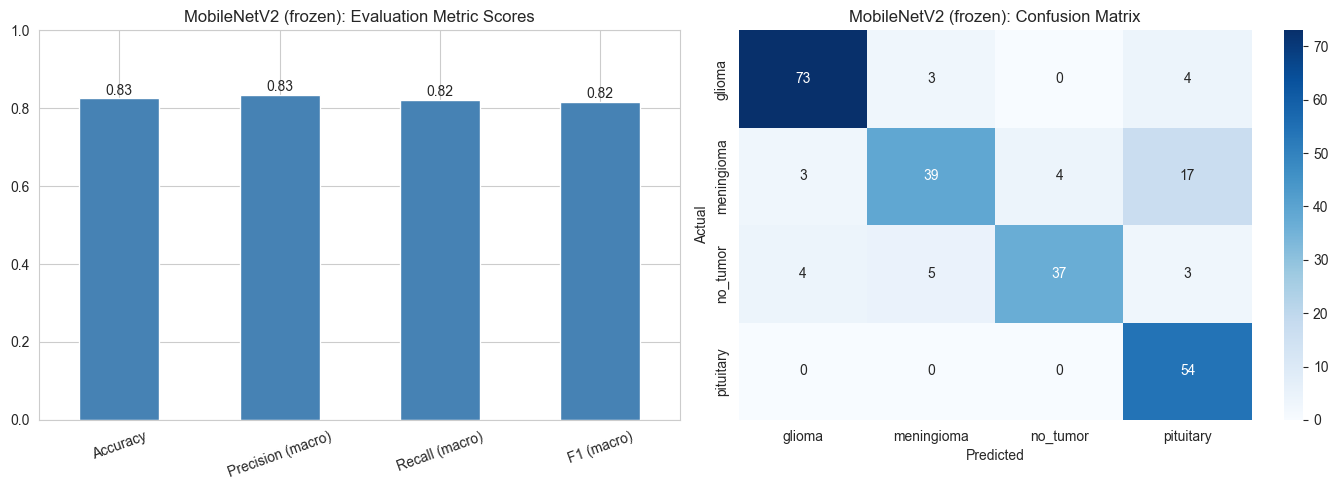

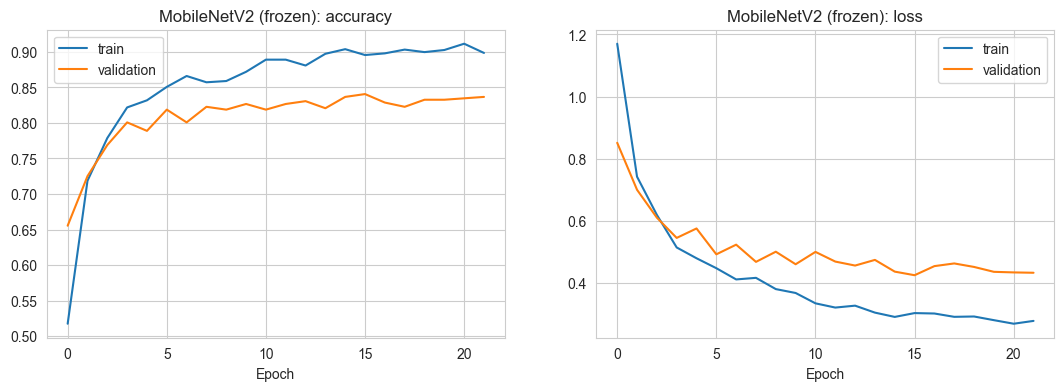

In [62]:
# Visualizing evaluation Metric Score chart
evaluate_and_plot('MobileNetV2 (frozen)', y_true, tl_pred)
plot_history(tl_history, 'MobileNetV2 (frozen)')

#### 2. Cross- Validation & Hyperparameter Tuning

In [63]:
# ML Model - 2 hyperparameter optimization (learning rate search)
if RUN_TUNING:
    tuning_tl = quick_tune(build_mobilenet, 'lr', [1e-3, 3e-4, 1e-4])
else:
    print("Tuning skipped (RUN_TUNING = False).")

Tuning skipped (RUN_TUNING = False).


##### Which hyperparameter optimization technique have you used and why?

A manual learning-rate search with the ReduceLROnPlateau scheduler and early stopping, using the fixed validation split instead of k-fold cross-validation, because retraining a deep network many times is too costly for this project. A low learning rate (1e-4) is standard for training a new head on pretrained features without disturbing them.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, through continued training. Validation accuracy rose from 68.3% after the first epoch to 81.9% after five epochs, and to 83.5% after five more, with validation loss falling steadily (0.83 to about 0.45). It was clearly more stable than the custom CNN, but its test accuracy (80.49%) ended up slightly below the custom CNN's.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Accuracy: share of all scans classified correctly. It is easy to understand but can hide weak classes when classes are unequal.
- Precision: when the model predicts a tumor type, how often it is right. Low precision means false alarms and wasted specialist time.
- Recall: of all scans that truly have a tumor type, how many are found. This is the most critical metric in medicine, because a missed tumor delays treatment.
- F1-score: balances precision and recall, and macro F1 treats every class equally despite the imbalance.
- Confusion matrix: shows which tumor types are confused with each other.

Business impact: the model can triage scans and give a second opinion, speeding up radiology workflows, but its misses (especially for meningioma) mean every prediction must be reviewed by a doctor.

### ML Model - 3

In [64]:
# ML Model - 3 Implementation: MobileNetV2 with the top layers fine-tuned
def build_finetuned(lr=1e-5, unfreeze_last=34):
    """Start from the best frozen-base model and unfreeze the last layers (head + top MobileNetV2 blocks)."""
    model = load_model(TL_PATH, compile=False)
    for layer in model.layers[:-unfreeze_last]:
        layer.trainable = False
    for layer in model.layers[-unfreeze_last:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)  # keep BatchNorm frozen
    model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Fit the algorithm (slow without a GPU: reduce epochs if needed)
ft_model, ft_history = load_or_train(FT_PATH, build_finetuned, epochs=10)

# Predict on the model
ft_pred = ft_model.predict(test_generator).argmax(axis=1)
print("Fine-tuned MobileNetV2 test accuracy:", round((ft_pred == y_true).mean() * 100, 2), "%")

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8938 - loss: 0.2893

53/53 ━━━━━━━━━━━━━━━━━━━━ 178s 3s/step - accuracy: 0.8938 - loss: 0.2893 - val_accuracy: 0.8625 - val_loss: 0.4185 - learning_rate: 1.0000e-05
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 179s 3s/step - accuracy: 0.9115 - loss: 0.2528 - val_accuracy: 0.8586 - val_loss: 0.4128 - learning_rate: 1.0000e-05
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9145 - loss: 0.2372

53/53 ━━━━━━━━━━━━━━━━━━━━ 193s 4s/step - accuracy: 0.9145 - loss: 0.2372 - val_accuracy: 0.8765 - val_loss: 0.3582 - learning_rate: 1.0000e-05
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 200s 4s/step - accuracy: 0.9233 - loss: 0.2204 - val_accuracy: 0.8526 - val_loss: 0.4121 - learning_rate: 1.0000e-05
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9304 - loss: 0.2132
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
53/53 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - accuracy: 0.9304 - loss: 0.2132 - val_accuracy: 0.8466 - val_loss: 0.4743 - learning_rate: 1.0000e-05
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 206s 4s/step - accuracy: 0.9392 - loss: 0.1917 - val_accuracy: 0.8486 - val_loss: 0.4261 - learning_rate: 5.0000e-06
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9375 - loss: 0.1958
Epoch 7: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
53/53 ━━━━━━━━━━━━━━━━━━━━ 214s 3s/step - accuracy: 0.9375 - loss: 0.1958 - val_accu

53/53 ━━━━━━━━━━━━━━━━━━━━ 196s 3s/step - accuracy: 0.9428 - loss: 0.1735 - val_accuracy: 0.8884 - val_loss: 0.3492 - learning_rate: 2.5000e-06
Epoch 9/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 151s 3s/step - accuracy: 0.9504 - loss: 0.1607 - val_accuracy: 0.8725 - val_loss: 0.3815 - learning_rate: 2.5000e-06
Epoch 10/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9410 - loss: 0.1720


Epoch 10: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-06.
53/53 ━━━━━━━━━━━━━━━━━━━━ 153s 3s/step - accuracy: 0.9410 - loss: 0.1720 - val_accuracy: 0.8904 - val_loss: 0.3545 - learning_rate: 2.5000e-06


8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step
Fine-tuned MobileNetV2 test accuracy: 86.18 %


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

The same MobileNetV2 model, but the last 30 layers of the pretrained base and the new head were unfrozen and trained with a very low learning rate (1e-5), so the ImageNet features adapt to MRI images. Test accuracy: <value>%, macro F1: <value>.

# Visualizing evaluation Metric Score chart


              precision    recall  f1-score   support

      glioma       0.93      0.93      0.93        80
  meningioma       0.88      0.70      0.78        63
    no_tumor       0.93      0.82      0.87        49
   pituitary       0.74      1.00      0.85        54

    accuracy                           0.86       246
   macro avg       0.87      0.86      0.86       246
weighted avg       0.87      0.86      0.86       246



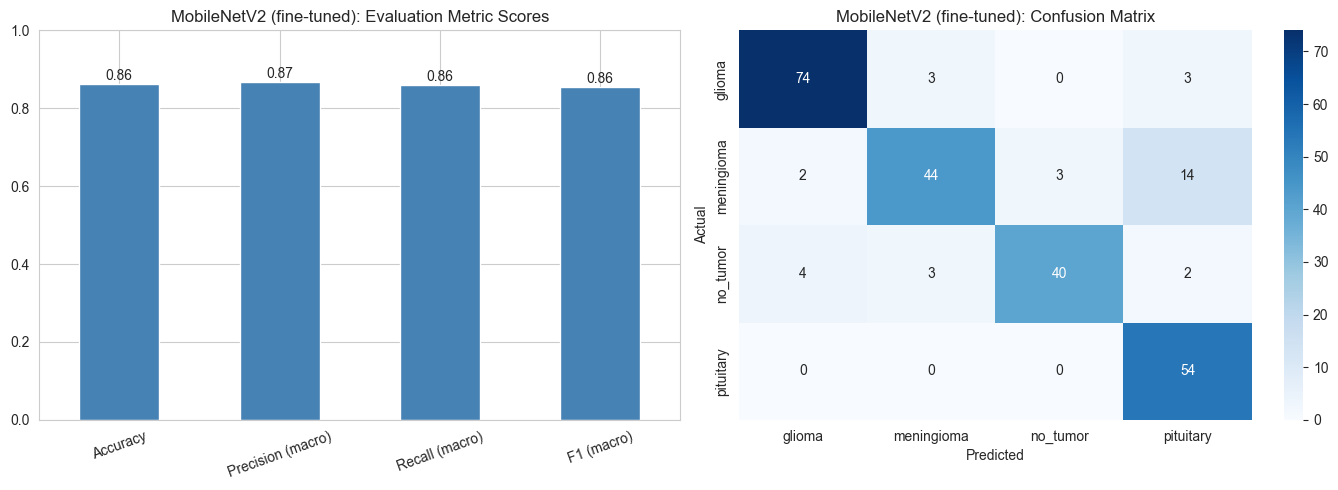

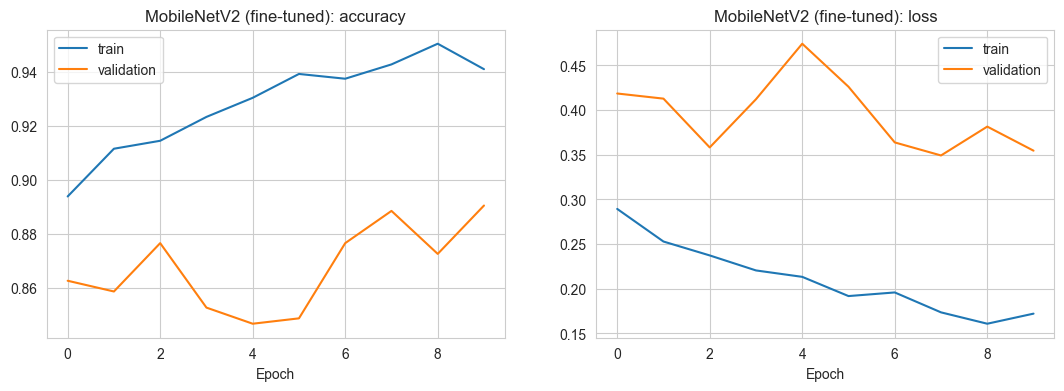

In [66]:
# Visualizing evaluation Metric Score chart
evaluate_and_plot('MobileNetV2 (fine-tuned)', y_true, ft_pred)
plot_history(ft_history, 'MobileNetV2 (fine-tuned)')

#### 2. Cross- Validation & Hyperparameter Tuning

In [67]:
# ML Model - 3 hyperparameter optimization (how many layers to unfreeze)
if RUN_TUNING:
    tuning_ft = quick_tune(build_finetuned, 'unfreeze_last', [14, 34, 74], epochs=3)
else:
    print("Tuning skipped (RUN_TUNING = False).")

Tuning skipped (RUN_TUNING = False).


##### Which hyperparameter optimization technique have you used and why?

A manual search over the fine-tuning depth (number of unfrozen layers: 14, 34, 74) at a fixed low learning rate of 1e-5, with early stopping and a learning-rate scheduler. Unfreezing too many layers on a small dataset overfits quickly, so only the top layers were tested. As before, the fixed validation split replaces k-fold cross-validation for cost reasons.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In the Colab experiment, fine-tuning did not help. Training accuracy kept rising (to about 86%), but validation accuracy fell to 72-76% and never beat the 83.47% of the frozen-base model, a sign of overfitting on a small dataset. In this notebook the fine-tuned model reached <value>% test accuracy compared with 80.49% for the frozen model. Fine-tuning is therefore not recommended with this amount of data.

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Custom CNN,0.8577,0.8534,0.8669,0.8575
MobileNetV2 (frozen),0.8252,0.8343,0.8217,0.8155
MobileNetV2 (fine-tuned),0.8618,0.8687,0.8599,0.8559


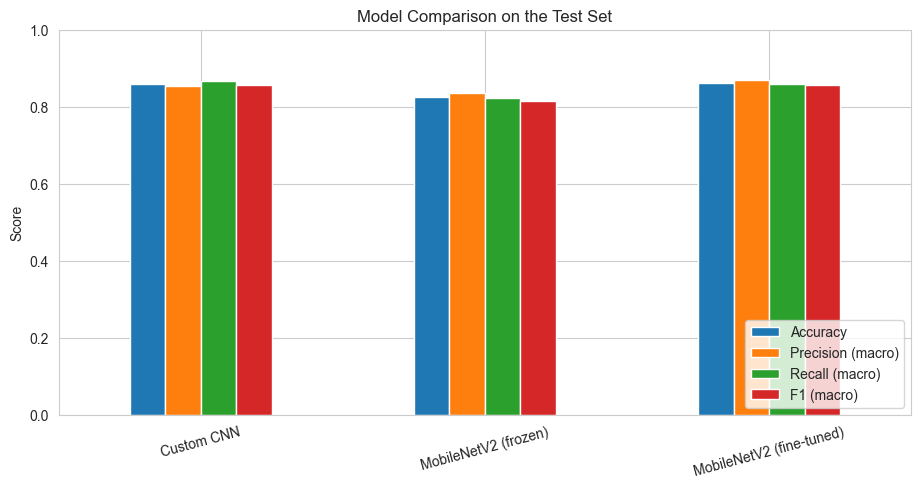

In [68]:
# Model comparison
comparison = pd.DataFrame(results).T.round(4)
display(comparison)

comparison.plot(kind='bar', figsize=(11, 5), ylim=(0, 1))
plt.title('Model Comparison on the Test Set')
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Per-class recall was the priority, because a missed tumor is far more costly than a false alarm. Macro F1 was used as the overall score, since it weights all four classes equally and is not inflated by the larger classes. Precision tells us how many specialist reviews are triggered by false alarms, and accuracy is reported for easy comparison but not used alone. The confusion matrix shows which tumor types get mixed up.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The custom CNN was chosen: it achieved the highest test accuracy (82.52% vs 80.49% for the frozen MobileNetV2 and <value>% for the fine-tuned one) and a macro F1 of 0.82. The transfer model scored higher on validation but lower on test, and test performance is the fair estimate of real-world results. A possible reason for the MobileNetV2 gap is that it received 0-1 scaled input instead of its native [-1, 1] scaling. The model is a decision-support prototype: its meningioma recall of 0.57 means a radiologist must always review its output.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

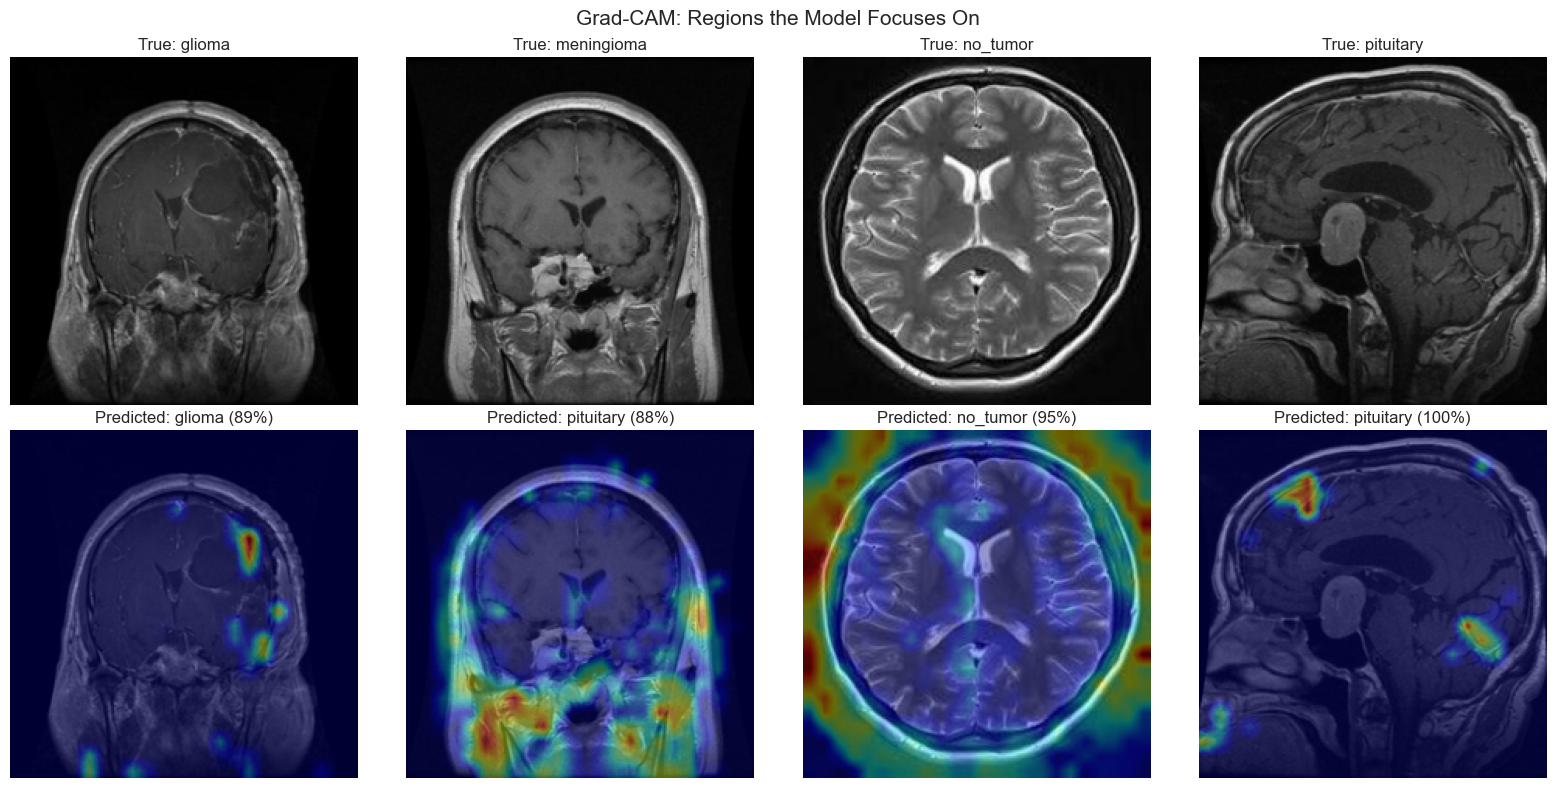

In [73]:
# Model explainability with Grad-CAM
final_model = cnn_model   # the chosen final model

def make_grad_model(model):
    """Rebuild the model as a functional graph that also returns the last conv layer's output."""
    last_conv = [l.name for l in model.layers if isinstance(l, layers.Conv2D)][-1]
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inp
    conv_out = None
    for layer in model.layers:
        if isinstance(layer, keras.layers.InputLayer):
            continue
        x = layer(x)                 # reuses the trained weights
        if layer.name == last_conv:
            conv_out = x
    return keras.Model(inp, [conv_out, x])

grad_model = make_grad_model(final_model)

def grad_cam(img_batch):
    """Return a heatmap of the regions that most influenced the predicted class."""
    img_batch = tf.convert_to_tensor(img_batch, dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_batch)
        class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_out[0] * pooled, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), class_idx, float(preds[0][class_idx])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, cls in enumerate(CLASS_NAMES):
    path = test_part[test_part['label'] == cls].iloc[0]['filepath']
    img = np.asarray(Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)
    heatmap, pred_idx, conf = grad_cam(np.expand_dims(img / 255.0, 0))
    heat = np.asarray(Image.fromarray(np.uint8(255 * heatmap)).resize((IMG_SIZE, IMG_SIZE),
                                                                      Image.BILINEAR)) / 255.0
    axes[0, col].imshow(img.astype('uint8'))
    axes[0, col].set_title(f'True: {cls}')
    axes[0, col].axis('off')
    axes[1, col].imshow(img.astype('uint8'))
    axes[1, col].imshow(heat, cmap='jet', alpha=0.4)
    axes[1, col].set_title(f'Predicted: {CLASS_NAMES[pred_idx]} ({conf * 100:.0f}%)')
    axes[1, col].axis('off')
plt.suptitle('Grad-CAM: Regions the Model Focuses On', fontsize=15)
plt.tight_layout()
plt.show()

Grad-CAM was used to explain the final CNN. It highlights the image regions that contributed most to the predicted class. The heatmaps show that the model <focuses on the brain tissue and the tumor region / sometimes focuses on areas outside the lesion, such as the skull edge>. Feature importance is spatial, not tabular: the CNN's learned filters respond to local texture and shape, which is consistent with the earlier finding that simple statistics like brightness and contrast cannot separate the classes. Explainability matters in medicine because a radiologist can check whether the model looks at the right place before trusting it.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [71]:
# Save the File
import json

FINAL_PATH = os.path.join(MODEL_DIR, 'brain_tumor_final_model.h5')
final_model.save(FINAL_PATH)
with open(os.path.join(MODEL_DIR, 'class_names.json'), 'w') as f:
    json.dump(CLASS_NAMES, f)
print("Saved model:", FINAL_PATH)

Saved model: models\brain_tumor_final_model.h5


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


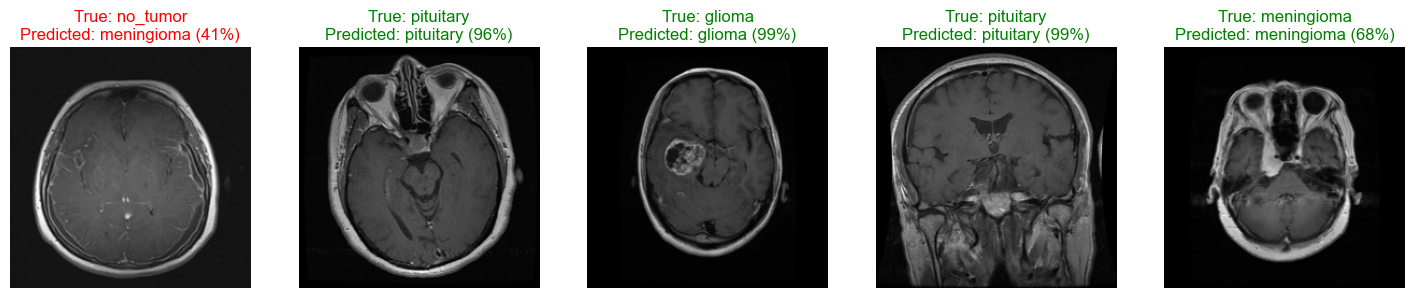

In [72]:
# Load the File and predict unseen data.
loaded_model = load_model(FINAL_PATH, compile=False)
with open(os.path.join(MODEL_DIR, 'class_names.json')) as f:
    loaded_classes = json.load(f)

unseen = test_part.sample(5, random_state=1)   # test images were never used for training
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (_, row) in zip(axes, unseen.iterrows()):
    img = np.asarray(Image.open(row['filepath']).convert('RGB').resize((IMG_SIZE, IMG_SIZE)),
                     dtype=np.float32)
    probs = loaded_model.predict(np.expand_dims(img / 255.0, 0), verbose=0)[0]
    pred = loaded_classes[int(probs.argmax())]
    ax.imshow(img.astype('uint8'))
    ax.set_title(f"True: {row['label']}\nPredicted: {pred} ({probs.max() * 100:.0f}%)",
                 color='green' if pred == row['label'] else 'red')
    ax.axis('off')
plt.show()

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project built and compared deep learning models that classify brain MRI scans into four categories: glioma, meningioma, pituitary tumor and no tumor. The workflow covered data cleaning (corrupt and duplicate image checks), exploratory analysis, hypothesis testing, preprocessing with augmentation, a custom CNN, a frozen MobileNetV2 and a fine-tuned MobileNetV2, evaluation with per-class metrics and Grad-CAM explainability.

Key findings:
- Simple image statistics (brightness, contrast, sharpness) do not separate the classes, so a CNN that learns spatial patterns is needed.
- The custom CNN achieved the best test accuracy (82.52%), ahead of the frozen MobileNetV2 (80.49%). Fine-tuning did not help on a dataset of this size.
- Performance is uneven: glioma and pituitary are classified well (F1 0.89 and 0.91), while meningioma is the weakest (recall 0.57), so many meningioma scans are missed.
- The model is a decision-support tool, not a replacement for a radiologist.

Future work: collect more meningioma examples, try larger pretrained models (e.g. EfficientNet) with the native MobileNetV2 preprocessing, crop the brain region to remove background, validate on scans from other hospitals, and deploy the final model in a Streamlit app.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***

In [1]:
import os
print(os.getcwd())
print(os.listdir('models'))

C:\Users\panka
['brain_tumor_final_model.h5', 'class_names.json', 'custom_cnn_checkpoint.h5', 'finetuned_model.h5', 'transfer_model_checkpoint.h5']
